In [1]:
import os, shutil, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve, average_precision_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, StratifiedGroupKFold, learning_curve
from sklearn.inspection import permutation_importance
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
SEED = 42
T0 = time.time()
DATA = "data"
REQUIRED = ["osmi_mental_health_tech_2014.csv", "sleep_health_lifestyle.csv", "eeg-eye-state.csv"]

# Colab: upload the 3 CSVs if they are not already in ./data/
if not all(os.path.exists(os.path.join(DATA, f)) for f in REQUIRED):
    os.makedirs(DATA, exist_ok=True)
    try:
        from google.colab import files
        print("Upload these files:", REQUIRED)
        up = files.upload()
        for f in up:
            shutil.move(f, os.path.join(DATA, f))
    except ImportError:
        raise FileNotFoundError("Put the 3 CSV files in ./data/ and run again.")
print({f: os.path.exists(os.path.join(DATA, f)) for f in REQUIRED})

{'osmi_mental_health_tech_2014.csv': True, 'sleep_health_lifestyle.csv': True, 'eeg-eye-state.csv': True}


In [2]:
MENTAL_GROUPS = {
    "About you": ["Age", "Gender", "family_history"],
    "Work setting": ["remote_work", "tech_company", "no_employees"],
    "Workplace support": ["benefits", "care_options", "wellness_program", "seek_help", "anonymity", "leave"],
    "Workplace culture": ["mental_health_consequence", "coworkers", "supervisor"],
}
SLEEP_GROUPS = {
    "Demographics": ["Age", "Gender", "Occupation"],
    "Sleep & activity": ["Sleep Duration", "Quality of Sleep", "Physical Activity Level", "Daily Steps"],
    "Body & vitals": ["BMI Category", "Systolic", "Diastolic", "Heart Rate"],
    "Self-rated stress": ["Stress Level"],
}
STRESS_GROUPS = {
    "Demographics": ["Age", "Gender", "Occupation"],
    "Sleep & activity": ["Sleep Duration", "Quality of Sleep", "Physical Activity Level", "Daily Steps"],
    "Body & vitals": ["BMI Category", "Systolic", "Diastolic", "Heart Rate"],
}
GROUPS = {"mental": MENTAL_GROUPS, "sleep": SLEEP_GROUPS, "stress": STRESS_GROUPS}
MENTAL_FEATS = [f for g in MENTAL_GROUPS.values() for f in g]
SLEEP_FEATS = [f for g in SLEEP_GROUPS.values() for f in g]
STRESS_FEATS = [f for f in SLEEP_FEATS if f != "Stress Level"]
TASKS = ["mental", "sleep", "stress"]
TASK_NAME = {"mental": "Mental Well-being Support Need", "sleep": "Sleep-Disorder Risk", "stress": "High-Stress Indicator"}

def sleep_base():
    d = pd.read_csv(os.path.join(DATA, "sleep_health_lifestyle.csv"))
    bp = d["Blood Pressure"].str.split("/", expand=True).astype(int)
    d["Systolic"], d["Diastolic"] = bp[0], bp[1]
    d["BMI Category"] = d["BMI Category"].replace({"Normal Weight": "Normal"})
    d["Occupation"] = d["Occupation"].replace({"Software Engineer": "Engineer", "Sales Representative": "Salesperson",
                                               "Scientist": "Other", "Manager": "Other"})
    return d

FEMALE = {"female", "f", "woman", "cis female", "cis-female/femme", "femail", "female (cis)", "female ", "trans-female", "trans woman", "female (trans)"}
MALE = {"male", "m", "man", "cis male", "male-ish", "maile", "mal", "male (cis)", "make", "male ", "msle", "mail", "malr", "cis man", "guy (-ish) ^_^", "something kinda male?"}

def load_task(task):
    if task == "mental":
        d = pd.read_csv(os.path.join(DATA, "osmi_mental_health_tech_2014.csv"))
        d = d[(d.Age >= 18) & (d.Age <= 75)].copy()                  # impossible ages removed
        g = d.Gender.str.lower().str.strip()
        d["Gender"] = np.where(g.isin(FEMALE), "Female", np.where(g.isin(MALE), "Male", "Other"))
        y = (d["treatment"] == "Yes").astype(int)
        X = d[MENTAL_FEATS].assign(_y=y.values).drop_duplicates().reset_index(drop=True)  # exact duplicates removed
        y = X.pop("_y")
        return X, y, None
    d = sleep_base()
    if task == "sleep":
        y, feats = d["Sleep Disorder"].notna().astype(int), SLEEP_FEATS
    else:
        y, feats = (d["Stress Level"] >= 7).astype(int), STRESS_FEATS   # rating itself is NOT an input
    X = d[feats].reset_index(drop=True)
    groups = X.astype(str).agg("|".join, axis=1).factorize()[0]          # identical profiles share a group
    return X, y.reset_index(drop=True), groups

for t in TASKS:
    X_, y_, g_ = load_task(t)
    print(f"{TASK_NAME[t]:32s} n={len(X_):5d}  features={X_.shape[1]:2d}  positives={int(y_.sum()):4d} ({y_.mean():.1%})  "
          f"{'group-aware' if g_ is not None else 'stratified'} folds")

Mental Well-being Support Need   n= 1246  features=15  positives= 630 (50.6%)  stratified folds


Sleep-Disorder Risk              n=  374  features=12  positives= 155 (41.4%)  group-aware folds


High-Stress Indicator            n=  374  features=11  positives= 120 (32.1%)  group-aware folds


In [3]:
def make_pre(X):
    cat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    num = [c for c in X.columns if c not in cat]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])

def zoo(X):
    P = lambda est: Pipeline([("pre", make_pre(X)), ("clf", est)])
    return {
        "Logistic Regression": (P(LogisticRegression(max_iter=5000, random_state=SEED)), {"clf__C": [0.03, 0.1, 0.3, 1, 3, 10]}),
        "Random Forest": (P(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
                          {"clf__max_depth": [None, 4, 8], "clf__min_samples_leaf": [1, 3, 5]}),
        "Gradient Boosting": (P(GradientBoostingClassifier(random_state=SEED)),
                              {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 3]}),
        "SVM (RBF)": (P(SVC(probability=True, random_state=SEED)), {"clf__C": [0.5, 1, 5], "clf__gamma": ["scale", 0.01]}),
        "Neural Network (MLP)": (P(MLPClassifier(max_iter=3000, random_state=SEED)),
                                 {"clf__hidden_layer_sizes": [(32,), (64, 32)], "clf__alpha": [1e-3, 1e-2, 1e-1]}),
    }

METRICS = ["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC_AUC", "Brier"]

def scores(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return dict(Accuracy=accuracy_score(y, yh), Precision=precision_score(y, yh, zero_division=0),
                Recall=recall_score(y, yh), Specificity=tn / (tn + fp), F1=f1_score(y, yh),
                ROC_AUC=roc_auc_score(y, p), Brier=brier_score_loss(y, p))

def make_splits(y, groups=None, seed=SEED):
    y = np.asarray(y); dummy = np.zeros(len(y))
    if groups is None:
        return list(StratifiedKFold(5, shuffle=True, random_state=seed).split(dummy, y))
    return list(StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(dummy, y, groups))

def cv_model(pipe, grid, X, y, groups, splits):
    rows, oof, chosen = [], np.zeros(len(y)), []
    for tr, te in splits:
        Xtr, ytr = X.iloc[tr], y.iloc[tr]
        if grid:
            inner = make_splits(ytr.values, None if groups is None else groups[tr])
            gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=inner, n_jobs=-1).fit(Xtr, ytr)
            est = gs.best_estimator_; chosen.append(gs.best_params_)
        else:
            est = clone(pipe).fit(Xtr, ytr)
        p = est.predict_proba(X.iloc[te])[:, 1]
        oof[te] = p
        rows.append(scores(y.iloc[te].values, p))
    return pd.DataFrame(rows), oof, chosen

In [4]:
MODEL_ORDER = ["Baseline (majority class)", "Logistic Regression", "Random Forest",
               "Gradient Boosting", "SVM (RBF)", "Neural Network (MLP)"]
RESULTS = {}

def run_task(task):
    X, y, groups = load_task(task)
    splits = make_splits(y.values, groups)
    print(f"\n### {TASK_NAME[task]}  (n={len(X)}, features={X.shape[1]}, 5-fold {'group-aware' if groups is not None else 'stratified'})")
    pipes = {"Baseline (majority class)": (Pipeline([("pre", make_pre(X)), ("clf", DummyClassifier(strategy="prior"))]), None)}
    pipes.update(zoo(X))
    table, oofs, auc_mean, chosen_all, fold_dfs = [], {}, {}, {}, {}
    for name in MODEL_ORDER:
        pipe, grid = pipes[name]
        df, oof, chosen = cv_model(pipe, grid, X, y, groups, splits)
        row = {"Model": name}
        for m in METRICS:
            row[m] = f"{df[m].mean():.3f} ± {df[m].std():.3f}"
        table.append(row); fold_dfs[name] = df; oofs[name] = oof; auc_mean[name] = float(df["ROC_AUC"].mean()); chosen_all[name] = chosen
        print(f"  {name:26s} ROC-AUC {df['ROC_AUC'].mean():.3f} ± {df['ROC_AUC'].std():.3f}")
    best = max(MODEL_ORDER[1:], key=lambda n: auc_mean[n])      # selection by CV only
    print(f"  -> best by 5-fold CV ROC-AUC: {best}")
    return dict(X=X, y=y, groups=groups, table=pd.DataFrame(table), oof=oofs, auc=auc_mean, best=best, folds=fold_dfs)

for t in TASKS:
    RESULTS[t] = run_task(t)
    print("\nFull metric table (mean ± std over 5 outer folds):")
    display(RESULTS[t]["table"])


### Mental Well-being Support Need  (n=1246, features=15, 5-fold stratified)
  Baseline (majority class)  ROC-AUC 0.500 ± 0.000
  Logistic Regression        ROC-AUC 0.771 ± 0.011
  Random Forest              ROC-AUC 0.779 ± 0.007
  Gradient Boosting          ROC-AUC 0.781 ± 0.013
  SVM (RBF)                  ROC-AUC 0.779 ± 0.009
  Neural Network (MLP)       ROC-AUC 0.697 ± 0.031
  -> best by 5-fold CV ROC-AUC: Gradient Boosting

Full metric table (mean ± std over 5 outer folds):


                       Model       Accuracy      Precision         Recall    Specificity             F1        ROC_AUC          Brier
0  Baseline (majority class)  0.506 ± 0.001  0.506 ± 0.001  1.000 ± 0.000  0.000 ± 0.000  0.672 ± 0.001  0.500 ± 0.000  0.250 ± 0.000
1        Logistic Regression  0.706 ± 0.024  0.715 ± 0.021  0.697 ± 0.051  0.716 ± 0.031  0.705 ± 0.032  0.771 ± 0.011  0.197 ± 0.004
2              Random Forest  0.708 ± 0.021  0.707 ± 0.010  0.721 ± 0.058  0.695 ± 0.024  0.713 ± 0.032  0.779 ± 0.007  0.198 ± 0.005
3          Gradient Boosting  0.705 ± 0.012  0.706 ± 0.013  0.714 ± 0.035  0.695 ± 0.028  0.709 ± 0.017  0.781 ± 0.013  0.192 ± 0.004
4                  SVM (RBF)  0.716 ± 0.031  0.732 ± 0.014  0.689 ± 0.073  0.744 ± 0.017  0.709 ± 0.045  0.779 ± 0.009  0.194 ± 0.007
5       Neural Network (MLP)  0.642 ± 0.028  0.649 ± 0.026  0.635 ± 0.036  0.649 ± 0.021  0.642 ± 0.031  0.697 ± 0.031  0.298 ± 0.030


### Sleep-Disorder Risk  (n=374, features=12, 5-fold group-aware)
  Baseline (majority class)  ROC-AUC 0.500 ± 0.000
  Logistic Regression        ROC-AUC 0.939 ± 0.024
  Random Forest              ROC-AUC 0.921 ± 0.025
  Gradient Boosting          ROC-AUC 0.935 ± 0.025
  SVM (RBF)                  ROC-AUC 0.935 ± 0.027
  Neural Network (MLP)       ROC-AUC 0.918 ± 0.033
  -> best by 5-fold CV ROC-AUC: Logistic Regression

Full metric table (mean ± std over 5 outer folds):


                       Model       Accuracy      Precision         Recall    Specificity             F1        ROC_AUC          Brier
0  Baseline (majority class)  0.586 ± 0.005  0.000 ± 0.000  0.000 ± 0.000  1.000 ± 0.000  0.000 ± 0.000  0.500 ± 0.000  0.243 ± 0.001
1        Logistic Regression  0.925 ± 0.007  0.902 ± 0.038  0.923 ± 0.054  0.927 ± 0.037  0.911 ± 0.010  0.939 ± 0.024  0.080 ± 0.016
2              Random Forest  0.933 ± 0.009  0.922 ± 0.053  0.923 ± 0.054  0.941 ± 0.047  0.920 ± 0.009  0.921 ± 0.025  0.073 ± 0.011
3          Gradient Boosting  0.933 ± 0.009  0.922 ± 0.053  0.923 ± 0.054  0.941 ± 0.047  0.920 ± 0.009  0.935 ± 0.025  0.064 ± 0.007
4                  SVM (RBF)  0.925 ± 0.007  0.902 ± 0.038  0.923 ± 0.054  0.927 ± 0.037  0.911 ± 0.010  0.935 ± 0.027  0.067 ± 0.007
5       Neural Network (MLP)  0.933 ± 0.009  0.919 ± 0.030  0.923 ± 0.054  0.941 ± 0.026  0.919 ± 0.014  0.918 ± 0.033  0.064 ± 0.011


### High-Stress Indicator  (n=374, features=11, 5-fold group-aware)
  Baseline (majority class)  ROC-AUC 0.500 ± 0.000
  Logistic Regression        ROC-AUC 0.998 ± 0.005
  Random Forest              ROC-AUC 0.998 ± 0.004
  Gradient Boosting          ROC-AUC 0.984 ± 0.018
  SVM (RBF)                  ROC-AUC 1.000 ± 0.001
  Neural Network (MLP)       ROC-AUC 0.998 ± 0.005
  -> best by 5-fold CV ROC-AUC: SVM (RBF)

Full metric table (mean ± std over 5 outer folds):


                       Model       Accuracy      Precision         Recall    Specificity             F1        ROC_AUC          Brier
0  Baseline (majority class)  0.679 ± 0.002  0.000 ± 0.000  0.000 ± 0.000  1.000 ± 0.000  0.000 ± 0.000  0.500 ± 0.000  0.218 ± 0.001
1        Logistic Regression  0.984 ± 0.011  0.953 ± 0.032  1.000 ± 0.000  0.976 ± 0.017  0.976 ± 0.017  0.998 ± 0.005  0.020 ± 0.015
2              Random Forest  0.968 ± 0.037  0.968 ± 0.032  0.933 ± 0.127  0.984 ± 0.016  0.945 ± 0.067  0.998 ± 0.004  0.023 ± 0.018
3          Gradient Boosting  0.965 ± 0.026  0.968 ± 0.032  0.925 ± 0.104  0.984 ± 0.016  0.942 ± 0.049  0.984 ± 0.018  0.032 ± 0.031
4                  SVM (RBF)  0.973 ± 0.039  0.992 ± 0.018  0.925 ± 0.126  0.996 ± 0.009  0.953 ± 0.071  1.000 ± 0.001  0.020 ± 0.028
5       Neural Network (MLP)  0.962 ± 0.049  0.963 ± 0.043  0.917 ± 0.128  0.984 ± 0.017  0.937 ± 0.085  0.998 ± 0.005  0.023 ± 0.031

## 3. Discrimination and calibration plots (pooled out-of-fold predictions)

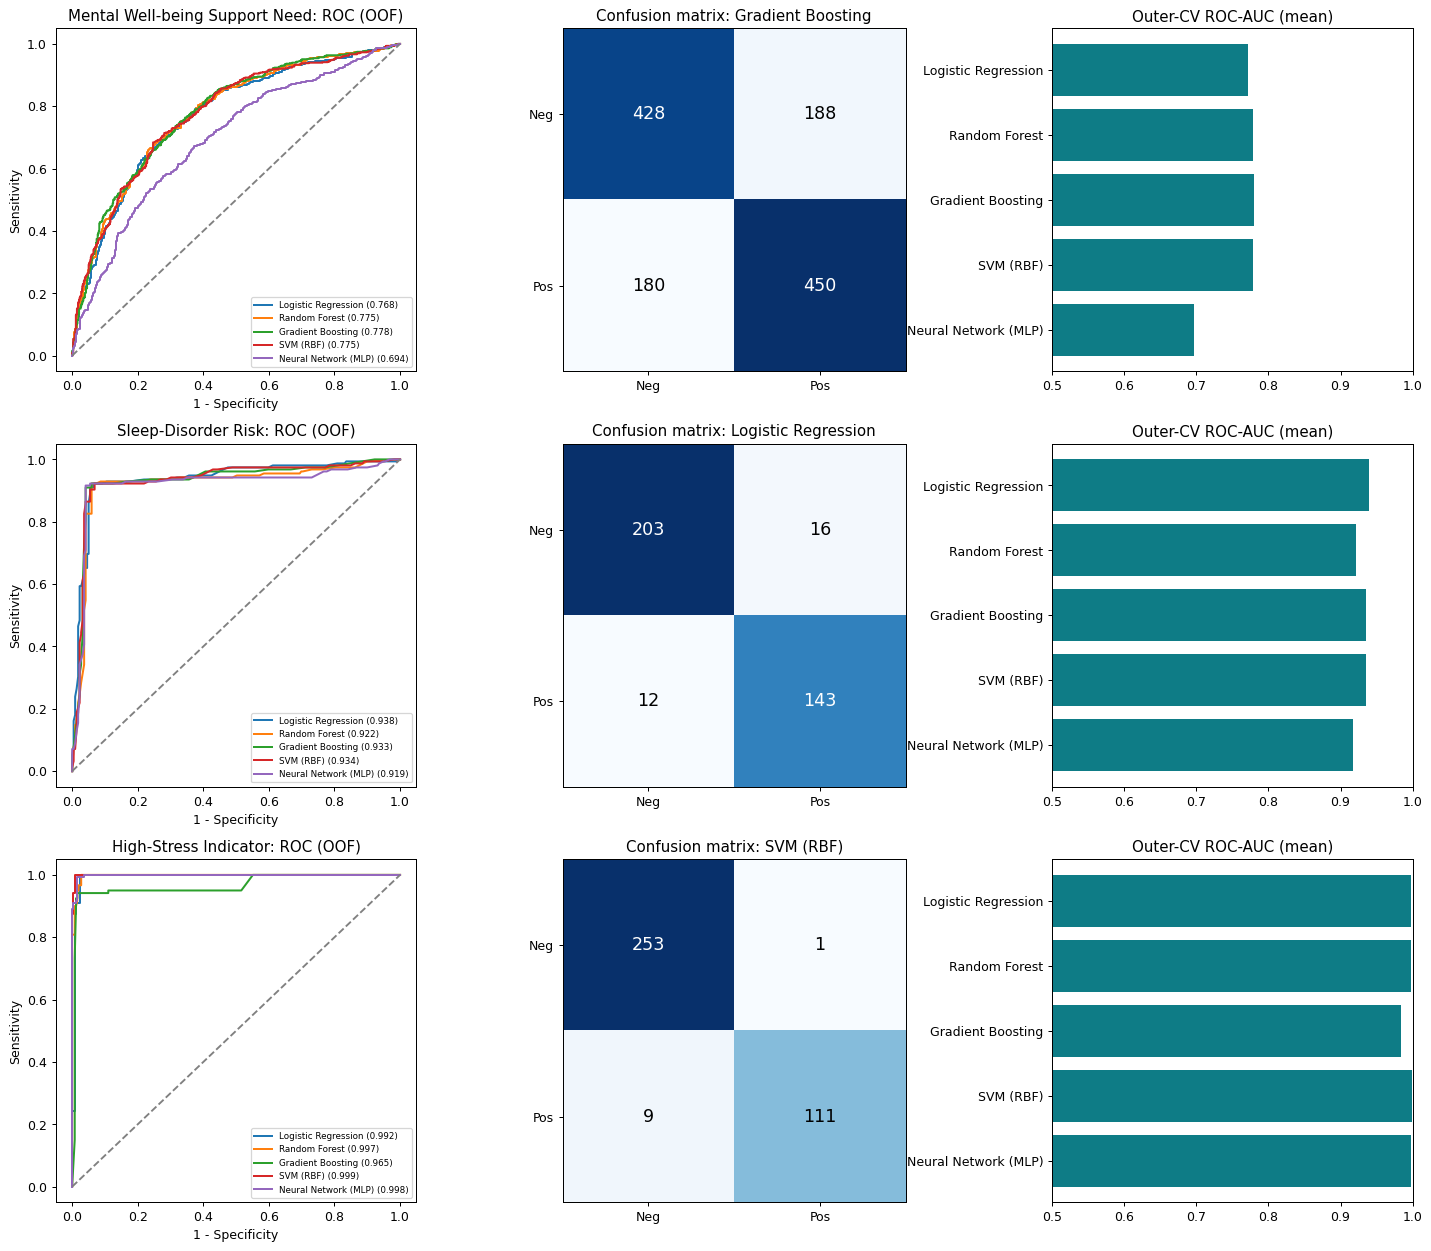

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for r, t in enumerate(TASKS):
    R = RESULTS[t]; y = R["y"].values
    ax = axes[r, 0]
    for name in MODEL_ORDER[1:]:
        fpr, tpr, _ = roc_curve(y, R["oof"][name])
        ax.plot(fpr, tpr, lw=1.6, label=f"{name} ({roc_auc_score(y, R['oof'][name]):.3f})")
    ax.plot([0, 1], [0, 1], "--", c="grey"); ax.set(title=f"{TASK_NAME[t]}: ROC (OOF)", xlabel="1 - Specificity", ylabel="Sensitivity")
    ax.legend(fontsize=7, loc="lower right")

    ax = axes[r, 1]; cm = confusion_matrix(y, (R["oof"][R["best"]] >= 0.5).astype(int))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=14, color="white" if v > cm.max() / 2 else "black")
    ax.set(title=f"Confusion matrix: {R['best']}", xticks=[0, 1], yticks=[0, 1], xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])

    ax = axes[r, 2]; names = MODEL_ORDER[1:]
    ax.barh(names[::-1], [R["auc"][n] for n in names][::-1], color="#0e7c86")
    ax.set(title="Outer-CV ROC-AUC (mean)", xlim=(0.5, 1.0))
fig.tight_layout(); plt.show()

In [6]:
def ablate(task):
    R = RESULTS[task]; X, y, groups, name = R["X"], R["y"], R["groups"], R["best"]
    splits = make_splits(y.values, groups)

    def evaluate(cols):
        Xs = X[cols]; pipe, grid = zoo(Xs)[name]
        df, _, _ = cv_model(pipe, grid, Xs, y, groups, splits)
        return df["ROC_AUC"].mean(), df["ROC_AUC"].std(), df["Accuracy"].mean(), df["F1"].mean()

    all_cols = list(X.columns)
    full = evaluate(all_cols)
    rows = [dict(Removed="None (full model)", Features=len(all_cols), ROC_AUC=round(full[0], 3),
                 AUC_std=round(full[1], 3), Delta_AUC=0.0, Accuracy=round(full[2], 3), F1=round(full[3], 3))]
    for g, feats in GROUPS[task].items():
        drop = [f for f in feats if f in all_cols]
        keep = [c for c in all_cols if c not in drop]
        if not keep:
            continue
        a = evaluate(keep)
        rows.append(dict(Removed=g, Features=len(keep), ROC_AUC=round(a[0], 3), AUC_std=round(a[1], 3),
                         Delta_AUC=round(a[0] - full[0], 3), Accuracy=round(a[2], 3), F1=round(a[3], 3)))
    return pd.DataFrame(rows), name

ABLATION = {}
for t in TASKS:
    ABLATION[t], best_name = ablate(t)
    print(f"\nAblation: {TASK_NAME[t]} using {best_name}")
    display(ABLATION[t])


Ablation: Mental Well-being Support Need using Gradient Boosting


             Removed  Features  ROC_AUC  AUC_std  Delta_AUC  Accuracy     F1
0  None (full model)        15    0.781    0.013      0.000     0.705  0.709
1          About you        12    0.708    0.025     -0.073     0.667  0.653
2       Work setting        12    0.778    0.012     -0.003     0.704  0.710
3  Workplace support         9    0.745    0.023     -0.036     0.698  0.694
4  Workplace culture        12    0.773    0.011     -0.007     0.696  0.699


Ablation: Sleep-Disorder Risk using Logistic Regression



Ablation: Sleep-Disorder Risk using Logistic Regression


             Removed  Features  ROC_AUC  AUC_std  Delta_AUC  Accuracy     F1
0  None (full model)        12    0.939    0.024      0.000     0.925  0.911
1       Demographics         9    0.941    0.031      0.001     0.928  0.914
2   Sleep & activity         8    0.937    0.024     -0.002     0.931  0.915
3      Body & vitals         8    0.925    0.032     -0.014     0.917  0.898
4  Self-rated stress        11    0.941    0.025      0.002     0.925  0.911


Ablation: High-Stress Indicator using SVM (RBF)


             Removed  Features  ROC_AUC  AUC_std  Delta_AUC  Accuracy     F1
0  None (full model)        11    1.000    0.001      0.000     0.973  0.953
1       Demographics         8    0.999    0.002     -0.001     0.973  0.955
2   Sleep & activity         7    0.945    0.071     -0.055     0.944  0.905
3      Body & vitals         7    0.997    0.004     -0.003     0.965  0.942

In [7]:
e = pd.read_csv(os.path.join(DATA, "eeg-eye-state.csv"))
Xe = e.iloc[:, :14].values.astype(float); ye = e["class"].values
med = np.median(Xe, 0); mad = np.median(np.abs(Xe - med), 0) * 1.4826
Xe = np.clip(Xe, med - 6 * mad, med + 6 * mad)                   # robust outlier clipping
blk = np.arange(len(Xe)) // (128 * 15)                           # contiguous 15-second blocks
EEG = {}
models_eeg = {
    "kNN": lambda: Pipeline([("s", StandardScaler()), ("m", KNeighborsClassifier(15))]),
    "Random Forest": lambda: RandomForestClassifier(200, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
}
for nm, mk in models_eeg.items():
    a = np.random.RandomState(1).rand(len(Xe)); rnd = a < 0.2
    m = mk().fit(Xe[~rnd], ye[~rnd]); pr = m.predict_proba(Xe[rnd])[:, 1]
    bte = blk % 5 == 4; m = mk().fit(Xe[~bte], ye[~bte]); pb = m.predict_proba(Xe[bte])[:, 1]
    EEG[nm] = dict(random_split=dict(acc=accuracy_score(ye[rnd], pr > .5), auc=roc_auc_score(ye[rnd], pr)),
                   blocked_split=dict(acc=accuracy_score(ye[bte], pb > .5), auc=roc_auc_score(ye[bte], pb)))
eeg_tab = pd.DataFrame([{"Model": k,
                         "Random split Acc": round(v["random_split"]["acc"], 3), "Random split AUC": round(v["random_split"]["auc"], 3),
                         "Blocked split Acc": round(v["blocked_split"]["acc"], 3), "Blocked split AUC": round(v["blocked_split"]["auc"], 3)}
                        for k, v in EEG.items()])
display(eeg_tab)
print("Near-perfect random-split scores are an autocorrelation artefact; with time-blocked splits the models are near chance.")

Near-perfect random-split scores are an autocorrelation artefact; with time-blocked splits the models are near chance.


           Model  Random split Acc  Random split AUC  Blocked split Acc  Blocked split AUC
0            kNN             0.939             0.987              0.397              0.625
1  Random Forest             0.914             0.978              0.439              0.650

### 6a. Exploratory data analysis

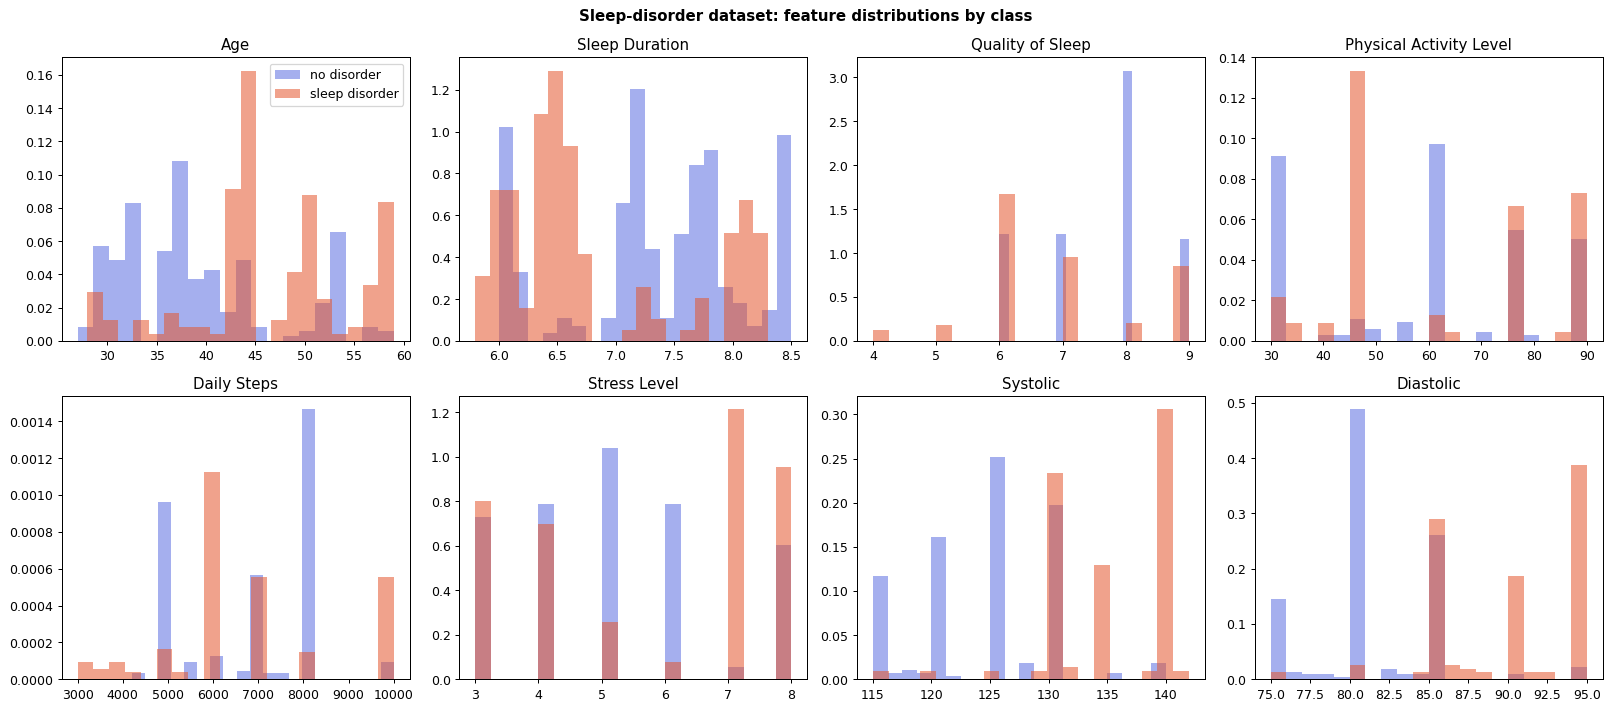

In [8]:
S = RESULTS["sleep"]; Xs, ys = S["X"], S["y"]
num_cols = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level", "Daily Steps", "Stress Level", "Systolic", "Diastolic"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(Xs.loc[ys == 0, c], bins=20, alpha=0.55, color="#5b6ee1", density=True, label="no disorder")
    ax.hist(Xs.loc[ys == 1, c], bins=20, alpha=0.55, color="#e4572e", density=True, label="sleep disorder")
    ax.set_title(c)
axes[0, 0].legend()
fig.suptitle("Sleep-disorder dataset: feature distributions by class", fontweight="bold")
fig.tight_layout(); plt.show()

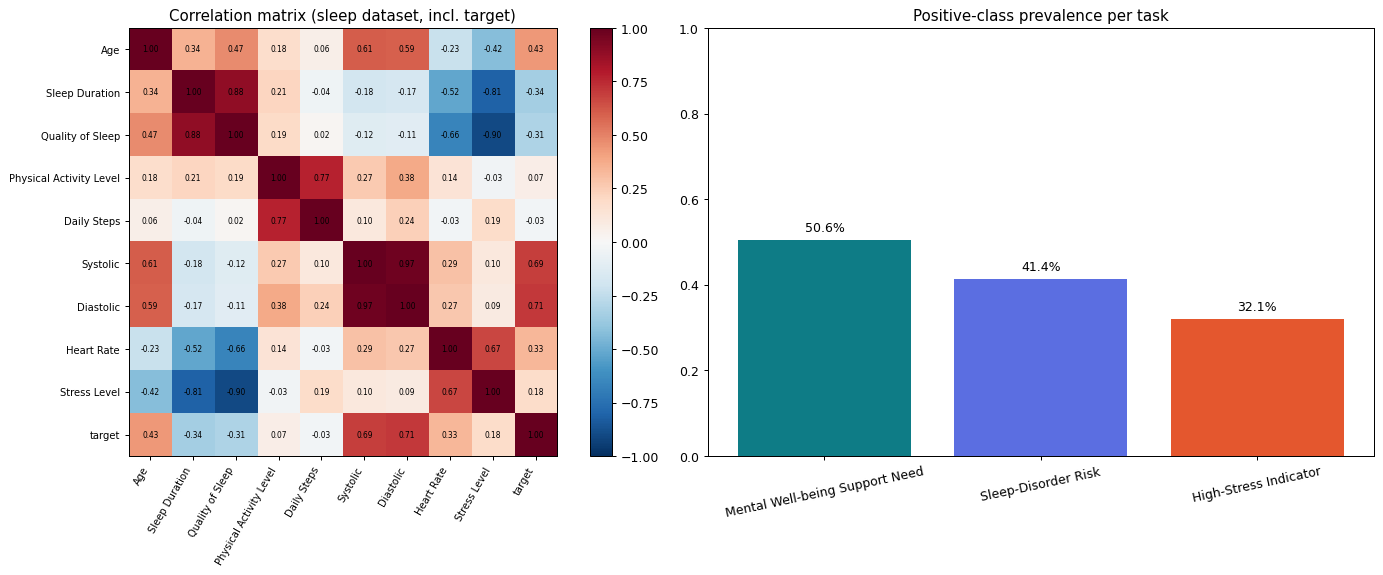

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
Xn = Xs.select_dtypes("number").copy(); Xn["target"] = ys.values
C = Xn.corr()
im = axes[0].imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(C))); axes[0].set_xticklabels(C.columns, rotation=60, ha="right", fontsize=8)
axes[0].set_yticks(range(len(C))); axes[0].set_yticklabels(C.columns, fontsize=8)
for i in range(len(C)):
    for j in range(len(C)):
        axes[0].text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[0].set_title("Correlation matrix (sleep dataset, incl. target)")
names = [TASK_NAME[t] for t in TASKS]; pos = [RESULTS[t]["y"].mean() for t in TASKS]
axes[1].bar(names, pos, color=["#0e7c86", "#5b6ee1", "#e4572e"]); axes[1].set_ylim(0, 1)
for i, p in enumerate(pos):
    axes[1].text(i, p + 0.02, f"{p:.1%}", ha="center")
axes[1].set_title("Positive-class prevalence per task"); axes[1].tick_params(axis="x", labelrotation=12)
fig.tight_layout(); plt.show()

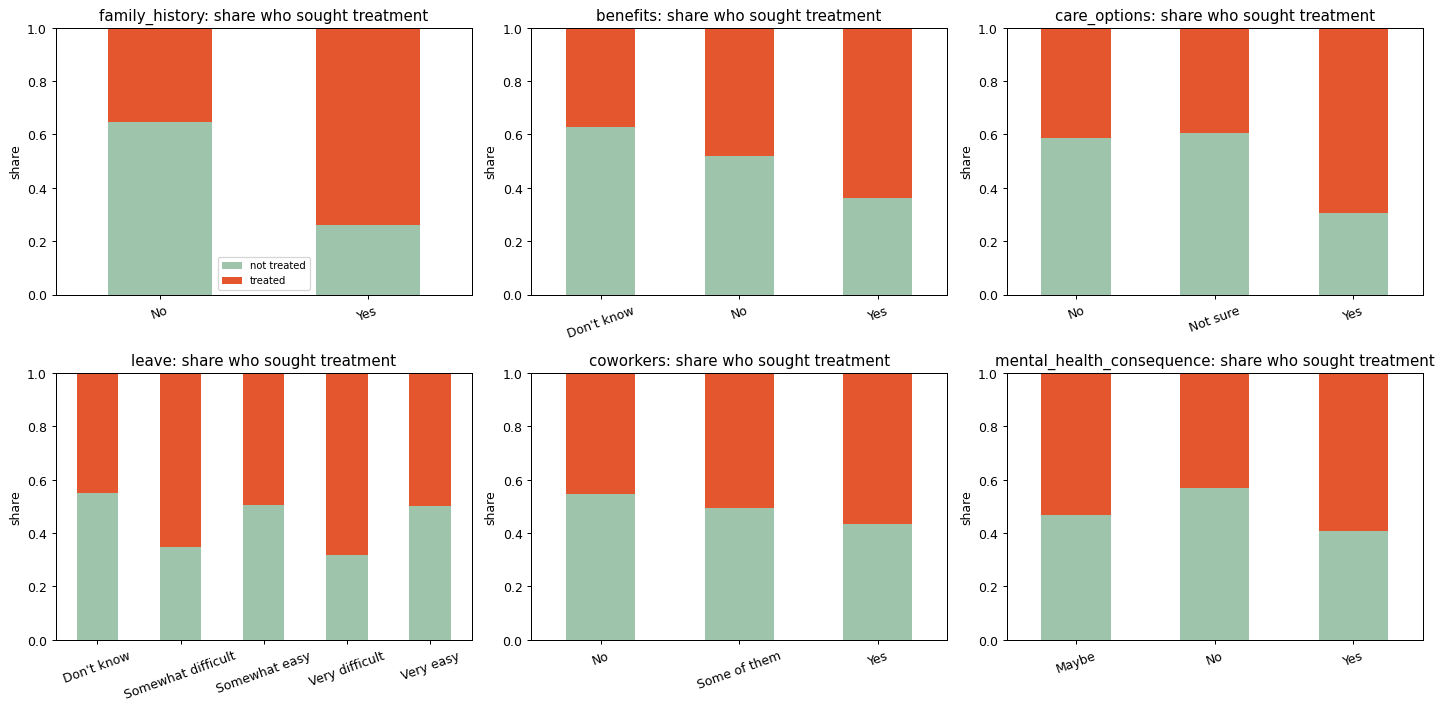

In [10]:
Xm, ym = RESULTS["mental"]["X"], RESULTS["mental"]["y"].values
cats = ["family_history", "benefits", "care_options", "leave", "coworkers", "mental_health_consequence"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cats):
    ct = pd.crosstab(Xm[c], ym, normalize="index")
    ct.plot(kind="bar", stacked=True, ax=ax, color=["#9ec5ab", "#e4572e"], legend=False, rot=20)
    ax.set_title(f"{c}: share who sought treatment"); ax.set_ylabel("share"); ax.set_xlabel(""); ax.set_ylim(0, 1)
axes[0, 0].legend(["not treated", "treated"], fontsize=8)
fig.tight_layout(); plt.show()

### 6b. Per-fold training results (outer 5-fold CV)

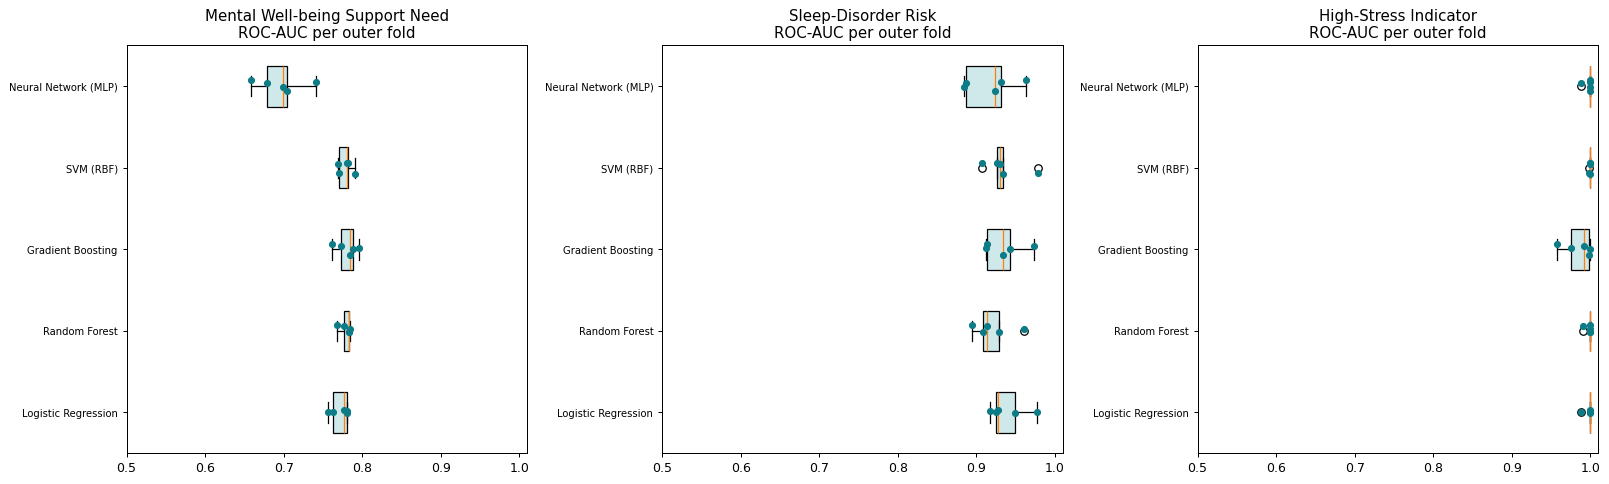

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, t in zip(axes, TASKS):
    R = RESULTS[t]; names = MODEL_ORDER[1:]
    data = [R["folds"][n]["ROC_AUC"].values for n in names]
    bp = ax.boxplot(data, vert=False, patch_artist=True)
    for patch in bp["boxes"]:
        patch.set_facecolor("#cfe8ea")
    rng = np.random.RandomState(0)
    for i, d in enumerate(data):
        ax.scatter(d, np.full(len(d), i + 1) + rng.uniform(-0.08, 0.08, len(d)), s=22, color="#0e7c86", zorder=3)
    ax.set_yticks(range(1, len(names) + 1)); ax.set_yticklabels(names, fontsize=8)
    ax.set_title(f"{TASK_NAME[t]}\nROC-AUC per outer fold"); ax.set_xlim(0.5, 1.01)
fig.tight_layout(); plt.show()

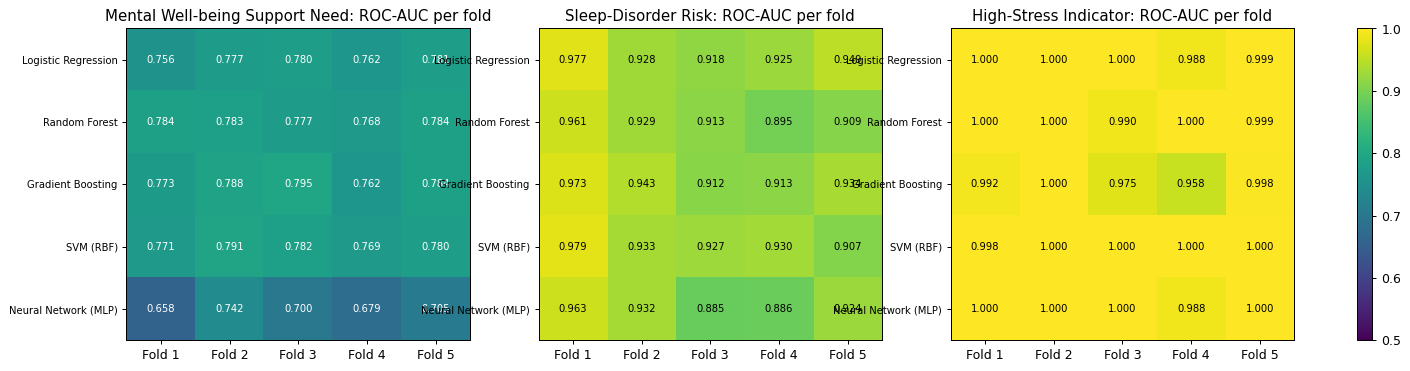

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, t in zip(axes, TASKS):
    R = RESULTS[t]; names = MODEL_ORDER[1:]
    M_ = np.array([R["folds"][n]["ROC_AUC"].values for n in names])
    im = ax.imshow(M_, cmap="viridis", vmin=0.5, vmax=1.0, aspect="auto")
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
    ax.set_xticks(range(5)); ax.set_xticklabels([f"Fold {i + 1}" for i in range(5)])
    for i in range(M_.shape[0]):
        for j in range(M_.shape[1]):
            ax.text(j, i, f"{M_[i, j]:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if M_[i, j] < 0.85 else "black")
    ax.set_title(f"{TASK_NAME[t]}: ROC-AUC per fold")
fig.colorbar(im, ax=axes, fraction=0.02)
plt.show()

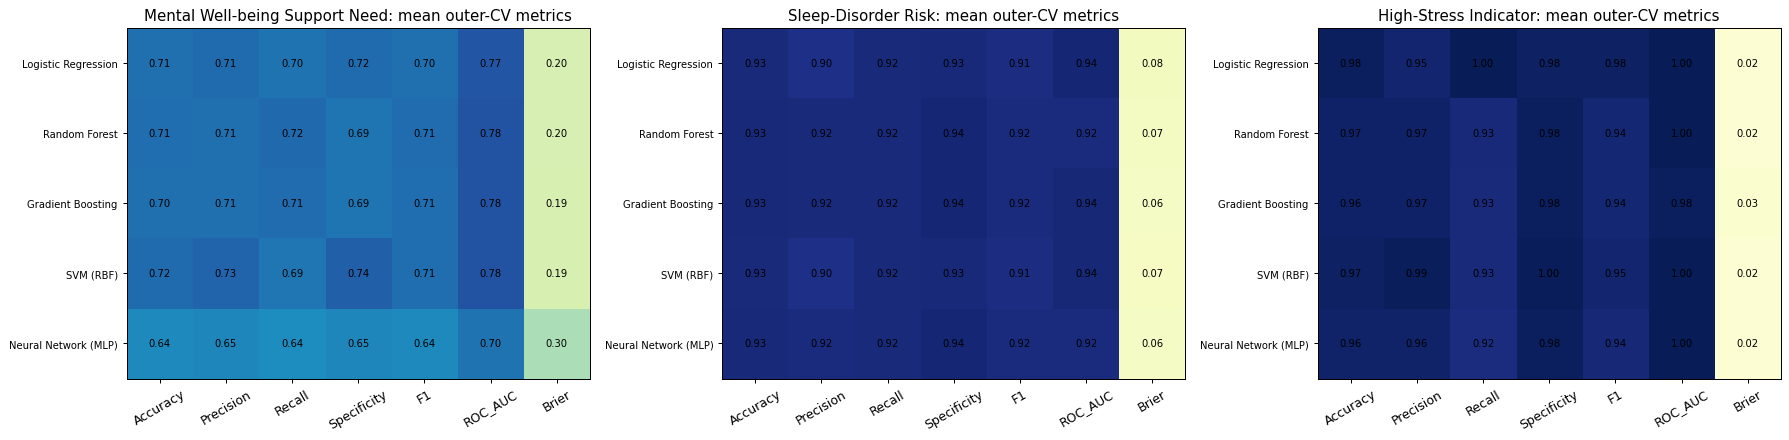

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, t in zip(axes, TASKS):
    tb = RESULTS[t]["table"].set_index("Model").loc[MODEL_ORDER[1:]]
    num = tb[METRICS].apply(lambda col: col.str.split(" ").str[0].astype(float))
    im = ax.imshow(num.values, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(METRICS))); ax.set_xticklabels(METRICS, rotation=30)
    ax.set_yticks(range(len(num))); ax.set_yticklabels(num.index, fontsize=8)
    for i in range(num.shape[0]):
        for j in range(num.shape[1]):
            ax.text(j, i, f"{num.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{TASK_NAME[t]}: mean outer-CV metrics")
fig.tight_layout(); plt.show()

### 6c. Probability quality: PR curves, reliability, separation, thresholds

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
for r, t in enumerate(TASKS):
    R = RESULTS[t]; y = R["y"].values
    ax = axes[r, 0]
    for n in MODEL_ORDER[1:]:
        p = R["oof"][n]; pr, rc, _ = precision_recall_curve(y, p)
        ax.plot(rc, pr, lw=1.6, label=f"{n} (AP {average_precision_score(y, p):.3f})")
    ax.axhline(y.mean(), ls="--", c="grey", label=f"chance ({y.mean():.2f})")
    ax.set(title=f"{TASK_NAME[t]}: Precision-Recall (OOF)", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
    ax.legend(fontsize=7, loc="lower left")

    ax = axes[r, 1]
    ax.plot([0, 1], [0, 1], "--", c="grey", label="perfect calibration")
    for n in MODEL_ORDER[1:]:
        p = R["oof"][n]; bins = np.linspace(0, 1, 11); idx = np.digitize(p, bins[1:-1])
        keep = [k for k in range(10) if (idx == k).sum() >= 5]
        ax.plot([p[idx == k].mean() for k in keep], [y[idx == k].mean() for k in keep], "o-", lw=1.4, ms=4, label=n)
    ax.set(title=f"{TASK_NAME[t]}: reliability diagram (OOF)", xlabel="Mean predicted probability",
           ylabel="Observed fraction positive", xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=7)

    ax = axes[r, 2]; p = R["oof"][R["best"]]
    ax.hist(p[y == 0], bins=25, alpha=0.6, color="#5b6ee1", label="negative", density=True)
    ax.hist(p[y == 1], bins=25, alpha=0.6, color="#e4572e", label="positive", density=True)
    ax.set(title=f"{R['best']}: predicted-probability separation", xlabel="Predicted P(positive)")
    ax.legend()
fig.tight_layout(); plt.show()

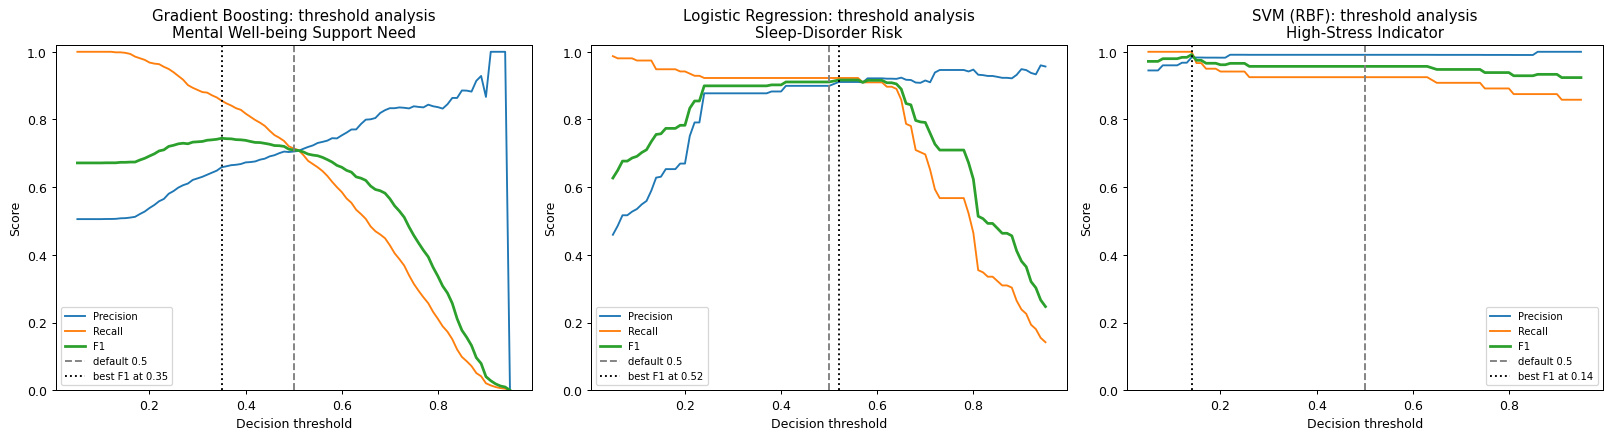

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ths = np.linspace(0.05, 0.95, 91)
for ax, t in zip(axes, TASKS):
    R = RESULTS[t]; y = R["y"].values; p = R["oof"][R["best"]]
    prec, rec, f1 = [], [], []
    for th in ths:
        yh = (p >= th).astype(int)
        prec.append(precision_score(y, yh, zero_division=0)); rec.append(recall_score(y, yh)); f1.append(f1_score(y, yh))
    ax.plot(ths, prec, label="Precision"); ax.plot(ths, rec, label="Recall"); ax.plot(ths, f1, label="F1", lw=2.2)
    best_th = ths[int(np.argmax(f1))]
    ax.axvline(0.5, ls="--", c="grey", label="default 0.5")
    ax.axvline(best_th, ls=":", c="black", label=f"best F1 at {best_th:.2f}")
    ax.set(title=f"{R['best']}: threshold analysis\n{TASK_NAME[t]}", xlabel="Decision threshold", ylabel="Score", ylim=(0, 1.02))
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

### 6d. Training dynamics: learning curves and MLP loss curves

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, t in zip(axes, TASKS):
    R = RESULTS[t]; X, y, g = R["X"], R["y"], R["groups"]
    pipe = zoo(X)[R["best"]][0]
    ts, tr_s, te_s = learning_curve(pipe, X, y, groups=g, cv=make_splits(y.values, g),
                                    train_sizes=np.linspace(0.2, 1.0, 5), scoring="roc_auc", n_jobs=-1)
    for arr, lab, col in [(tr_s, "train AUC", "#5b6ee1"), (te_s, "validation AUC", "#e4572e")]:
        ax.plot(ts, arr.mean(1), "o-", label=lab, color=col)
        ax.fill_between(ts, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=0.15, color=col)
    ax.set(title=f"{R['best']} learning curve\n{TASK_NAME[t]}", xlabel="Training samples", ylabel="ROC-AUC", ylim=(0.5, 1.01))
    ax.legend()
fig.tight_layout(); plt.show()

Mental Well-being Support Need: fold-1 held-out accuracy 0.720
Sleep-Disorder Risk: fold-1 held-out accuracy 0.760
High-Stress Indicator: fold-1 held-out accuracy 0.987


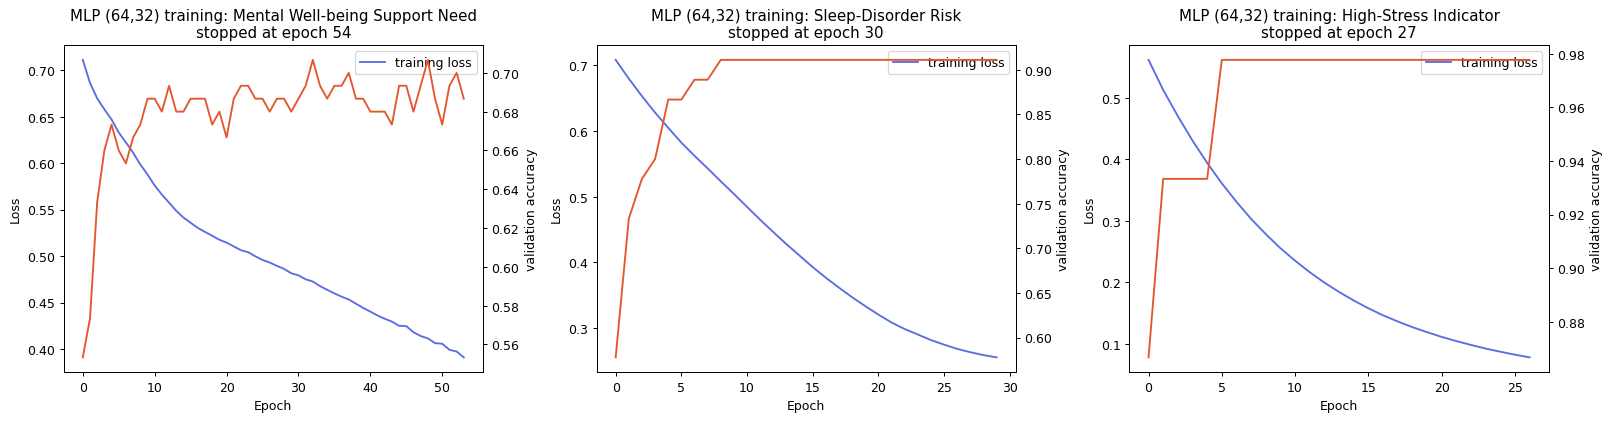

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, t in zip(axes, TASKS):
    X, y = RESULTS[t]["X"], RESULTS[t]["y"]
    tr, va = make_splits(y.values, RESULTS[t]["groups"])[0]
    mlp = Pipeline([("pre", make_pre(X)), ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-2,
                    learning_rate_init=1e-3, max_iter=400, early_stopping=True, validation_fraction=0.15,
                    n_iter_no_change=20, random_state=SEED))])
    mlp.fit(X.iloc[tr], y.iloc[tr])
    clf = mlp.named_steps["clf"]
    ax.plot(clf.loss_curve_, label="training loss", color="#5b6ee1")
    ax2 = ax.twinx(); ax2.plot(clf.validation_scores_, color="#e4572e", label="validation accuracy")
    ax2.set_ylabel("validation accuracy")
    ax.set(title=f"MLP (64,32) training: {TASK_NAME[t]}\nstopped at epoch {clf.n_iter_}", xlabel="Epoch", ylabel="Loss")
    ax.legend(loc="upper right")
    print(f"{TASK_NAME[t]}: fold-1 held-out accuracy {mlp.score(X.iloc[va], y.iloc[va]):.3f}")
fig.tight_layout(); plt.show()

### 6e. Explainability: permutation importance and hyperparameter sensitivity

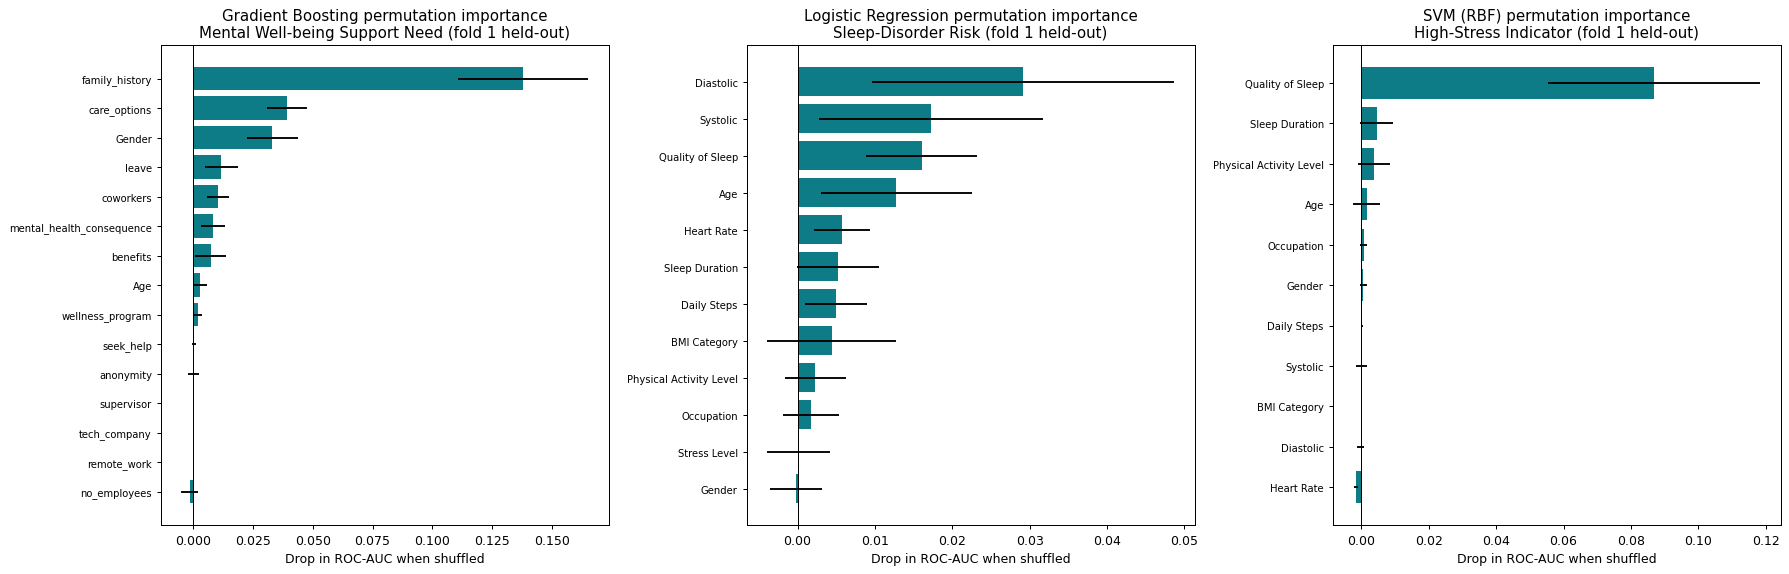

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, t in zip(axes, TASKS):
    R = RESULTS[t]; X, y, g = R["X"], R["y"], R["groups"]
    tr, te = make_splits(y.values, g)[0]
    pipe, grid = zoo(X)[R["best"]]
    gs = GridSearchCV(pipe, grid, scoring="roc_auc",
                      cv=make_splits(y.values[tr], None if g is None else g[tr]), n_jobs=-1).fit(X.iloc[tr], y.iloc[tr])
    pi = permutation_importance(gs.best_estimator_, X.iloc[te], y.iloc[te], scoring="roc_auc",
                                n_repeats=20, random_state=SEED, n_jobs=-1)
    order = np.argsort(pi.importances_mean)
    ax.barh(np.array(X.columns)[order], pi.importances_mean[order], xerr=pi.importances_std[order], color="#0e7c86")
    ax.axvline(0, c="black", lw=0.8)
    ax.set(title=f"{R['best']} permutation importance\n{TASK_NAME[t]} (fold 1 held-out)", xlabel="Drop in ROC-AUC when shuffled")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout(); plt.show()

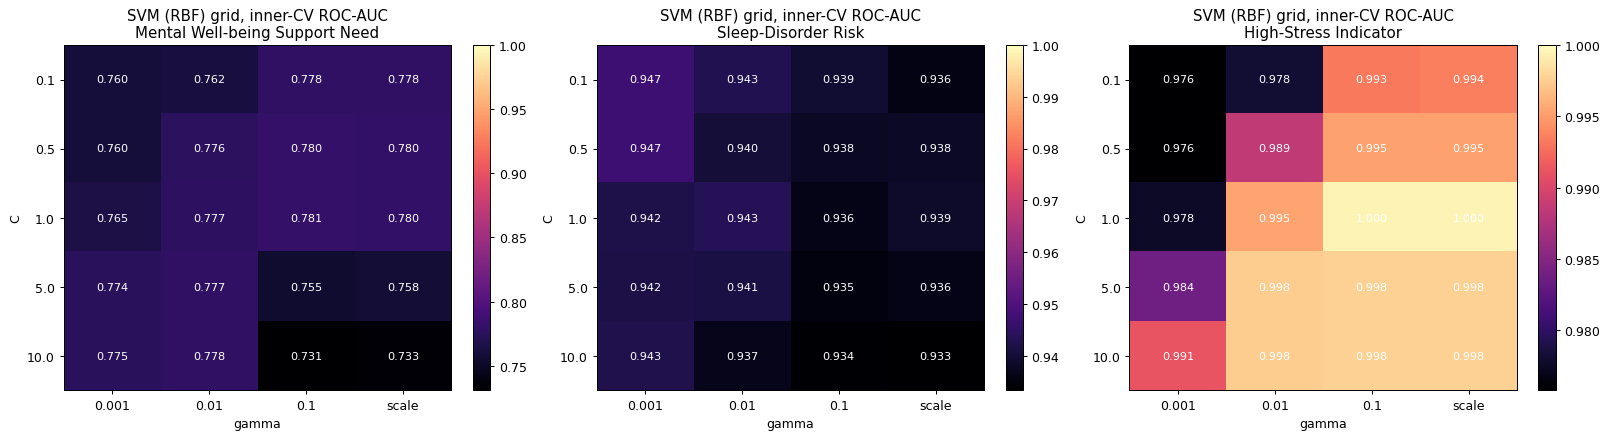

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, t in zip(axes, TASKS):
    R = RESULTS[t]; X, y, g = R["X"], R["y"], R["groups"]
    grid = {"clf__C": [0.1, 0.5, 1, 5, 10], "clf__gamma": ["scale", 0.001, 0.01, 0.1]}
    gs = GridSearchCV(zoo(X)["SVM (RBF)"][0], grid, scoring="roc_auc", cv=make_splits(y.values, g), n_jobs=-1).fit(X, y)
    d = pd.DataFrame(gs.cv_results_)
    piv = d.assign(gam=d["param_clf__gamma"].astype(str)).pivot_table(index="param_clf__C", columns="gam", values="mean_test_score")
    im = ax.imshow(piv.values, cmap="magma", vmin=max(0.5, piv.values.min()), vmax=1.0, aspect="auto")
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", fontsize=9, color="white")
    ax.set(title=f"SVM (RBF) grid, inner-CV ROC-AUC\n{TASK_NAME[t]}", xlabel="gamma", ylabel="C")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); plt.show()

### 6f. Ablation charts

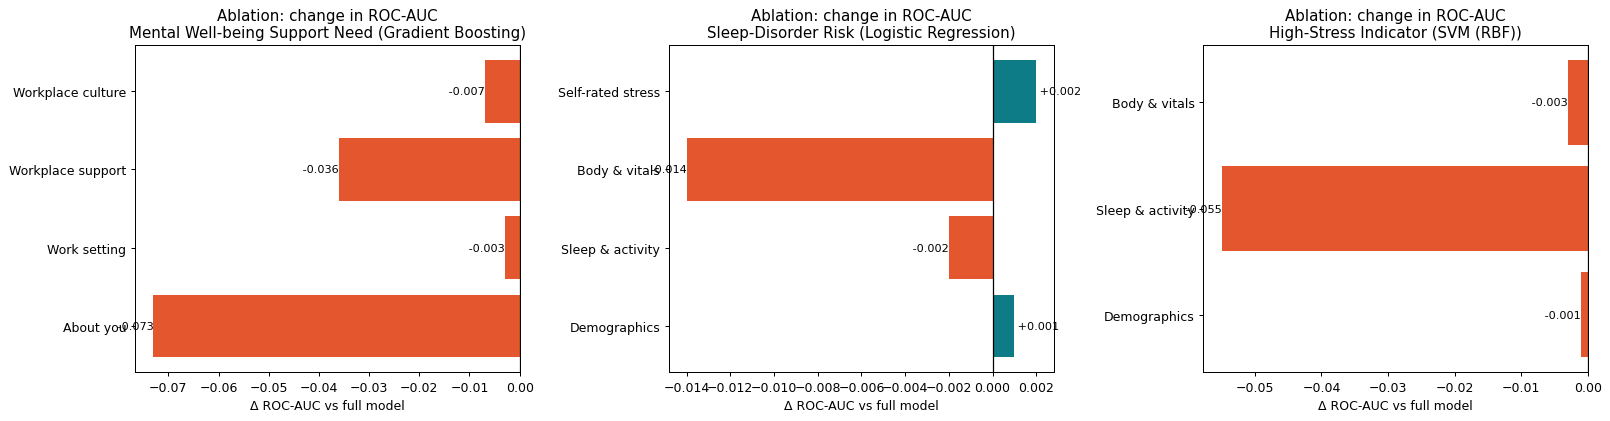

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, t in zip(axes, TASKS):
    A = ABLATION[t].iloc[1:]
    ax.barh(A["Removed"], A["Delta_AUC"], color=["#e4572e" if v < 0 else "#0e7c86" for v in A["Delta_AUC"]])
    ax.axvline(0, c="black", lw=1)
    for i, v in enumerate(A["Delta_AUC"]):
        ax.text(v, i, f" {v:+.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
    ax.set(title=f"Ablation: change in ROC-AUC\n{TASK_NAME[t]} ({RESULTS[t]['best']})", xlabel="Δ ROC-AUC vs full model")
fig.tight_layout(); plt.show()

### 6g. EEG study visuals

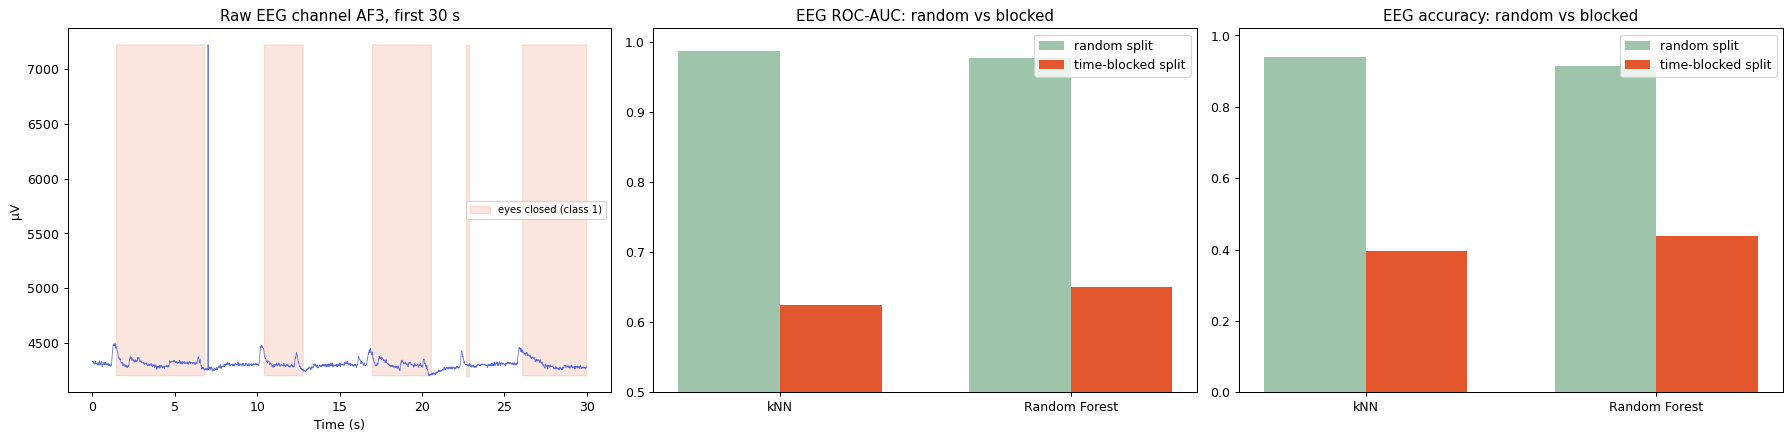

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
seg = 128 * 30; tt = np.arange(seg) / 128
ax = axes[0]
ax.plot(tt, e["AF3"].values[:seg], lw=0.6, color="#5b6ee1")
ax.fill_between(tt, e["AF3"].values[:seg].min(), e["AF3"].values[:seg].max(), where=ye[:seg] == 1,
                color="#e4572e", alpha=0.15, step="mid", label="eyes closed (class 1)")
ax.set(title="Raw EEG channel AF3, first 30 s", xlabel="Time (s)", ylabel="µV"); ax.legend(fontsize=8)
ax = axes[1]; x = np.arange(len(EEG)); w = 0.35
ax.bar(x - w / 2, [EEG[k]["random_split"]["auc"] for k in EEG], w, label="random split", color="#9ec5ab")
ax.bar(x + w / 2, [EEG[k]["blocked_split"]["auc"] for k in EEG], w, label="time-blocked split", color="#e4572e")
ax.set_xticks(x); ax.set_xticklabels(list(EEG)); ax.set_ylim(0.5, 1.02); ax.set_title("EEG ROC-AUC: random vs blocked"); ax.legend()
ax = axes[2]
ax.bar(x - w / 2, [EEG[k]["random_split"]["acc"] for k in EEG], w, label="random split", color="#9ec5ab")
ax.bar(x + w / 2, [EEG[k]["blocked_split"]["acc"] for k in EEG], w, label="time-blocked split", color="#e4572e")
ax.set_xticks(x); ax.set_xticklabels(list(EEG)); ax.set_ylim(0, 1.02); ax.set_title("EEG accuracy: random vs blocked"); ax.legend()
fig.tight_layout(); plt.show()

### 6h. Dashboard

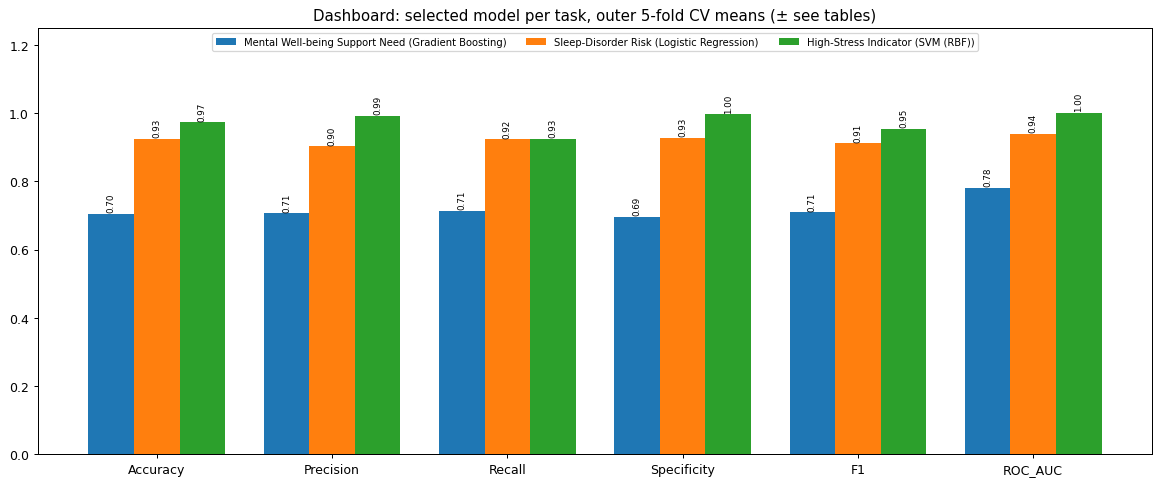

In [22]:
fig, ax = plt.subplots(figsize=(13, 5.5))
mets = ["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC_AUC"]
x = np.arange(len(mets)); w = 0.26
for k, t in enumerate(TASKS):
    R = RESULTS[t]; row = R["table"].set_index("Model").loc[R["best"]]
    vals = [float(row[m].split(" ")[0]) for m in mets]
    xs = x + (k - 1) * w
    ax.bar(xs, vals, w, label=f"{TASK_NAME[t]} ({R['best']})")
    for xi, v in zip(xs, vals):
        ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=7, rotation=90)
ax.set_xticks(x); ax.set_xticklabels(mets); ax.set_ylim(0, 1.25)
ax.legend(fontsize=8, loc="upper center", ncol=3)
ax.set_title("Dashboard: selected model per task, outer 5-fold CV means (± see tables)")
fig.tight_layout(); plt.show()

In [23]:
summary = {}
for t in TASKS:
    R = RESULTS[t]; b = R["best"]
    tab = R["table"].set_index("Model").loc[b]
    summary[t] = dict(task=TASK_NAME[t], selected_model=b, cv_roc_auc_mean=round(R["auc"][b], 4),
                      metrics={m: tab[m] for m in METRICS},
                      ablation=ABLATION[t].to_dict(orient="records"))
out = dict(seed=SEED, folds=5, main=summary, all_models={t: RESULTS[t]["table"].to_dict(orient="records") for t in TASKS},
           eeg_study=eeg_tab.to_dict(orient="records"))
with open("results_neuroergo.json", "w") as f:
    json.dump(out, f, indent=1, default=str)
print(f"Saved results_neuroergo.json   |   total runtime {time.time() - T0:.0f}s")
try:
    from google.colab import files
    files.download("results_neuroergo.json")
except ImportError:
    pass

Saved results_neuroergo.json   |   total runtime 1662s


In [24]:
import joblib, warnings
MODEL_FILES = ["mental.joblib", "sleep.joblib", "stress.joblib", "metrics.json"]
os.makedirs("models", exist_ok=True)
if not all(os.path.exists(os.path.join("models", f)) for f in MODEL_FILES):
    try:
        from google.colab import files
        print("Upload from the zip's models/ folder:", MODEL_FILES)
        up = files.upload()
        for f in up:
            shutil.move(f, os.path.join("models", f))
    except ImportError:
        raise FileNotFoundError("Put models/*.joblib and models/metrics.json in ./models/ and run again.")

import sklearn
print("scikit-learn in this runtime:", sklearn.__version__, "(bundles were saved with 1.9.1; pip install scikit-learn==1.9.1 to match exactly)")
MJ = json.load(open(os.path.join("models", "metrics.json")))
BUNDLES = {k: joblib.load(os.path.join("models", f"{k}.joblib")) for k in TASKS}
print("Loaded:", {k: type(v["model"]).__name__ for k, v in BUNDLES.items()})

scikit-learn in this runtime: 1.8.0 (bundles were saved with 1.9.1; pip install scikit-learn==1.9.1 to match exactly)
Loaded: {'mental': 'Pipeline', 'sleep': 'Pipeline', 'stress': 'Pipeline'}


In [25]:
rows = []
for k in TASKS:
    m, b = MJ["models"][k], BUNDLES[k]
    rows.append({
        "Task": TASK_NAME[k],
        "Deployed model": m["best_model"],
        "Pipeline": " -> ".join(type(s).__name__ for _, s in b["model"].steps),
        "Tuned hyperparameters": str(m["best_params"]),
        "Train / test": f'{m["n_train"]} / {m["n_test"]}',
        "Features": len(b["features"]),
        "Hold-out ROC-AUC": round(m["final"]["test"]["roc_auc"], 3),
        "95% CI (AUC)": f'{m["final"]["ci"]["roc_auc"][0]:.3f} to {m["final"]["ci"]["roc_auc"][1]:.3f}',
        "Repeated 5x3 CV AUC": f'{m["final"]["repeated_cv"]["roc_auc"]["mean"]:.3f} ± {m["final"]["repeated_cv"]["roc_auc"]["std"]:.3f}',
    })
display(pd.DataFrame(rows))
for k in TASKS:
    print(f"{TASK_NAME[k]}: {BUNDLES[k]['model'].steps[-1][1]}")

Mental Well-being Support Need: SVC(C=0.5, probability=True, random_state=42)
Sleep-Disorder Risk: LogisticRegression(C=0.3, max_iter=5000, random_state=42)
High-Stress Indicator: SVC(C=5, probability=True, random_state=42)


                             Task       Deployed model                                 Pipeline         Tuned hyperparameters Train / test  Features  Hold-out ROC-AUC    95% CI (AUC) Repeated 5x3 CV AUC
0  Mental Well-being Support Need            SVM (RBF)                 ColumnTransformer -> SVC  {'C': 0.5, 'gamma': 'scale'}    996 / 250        15             0.786  0.730 to 0.840       0.779 ± 0.016
1             Sleep-Disorder Risk  Logistic Regression  ColumnTransformer -> LogisticRegression                    {'C': 0.3}     311 / 63        12             0.968  0.914 to 1.000       0.934 ± 0.036
2           High-Stress Indicator            SVM (RBF)                 ColumnTransformer -> SVC    {'C': 5, 'gamma': 'scale'}     288 / 86        11             1.000  1.000 to 1.000       0.999 ± 0.003

### 7a. All candidate models: CV AUC vs hold-out AUC (from the training run)

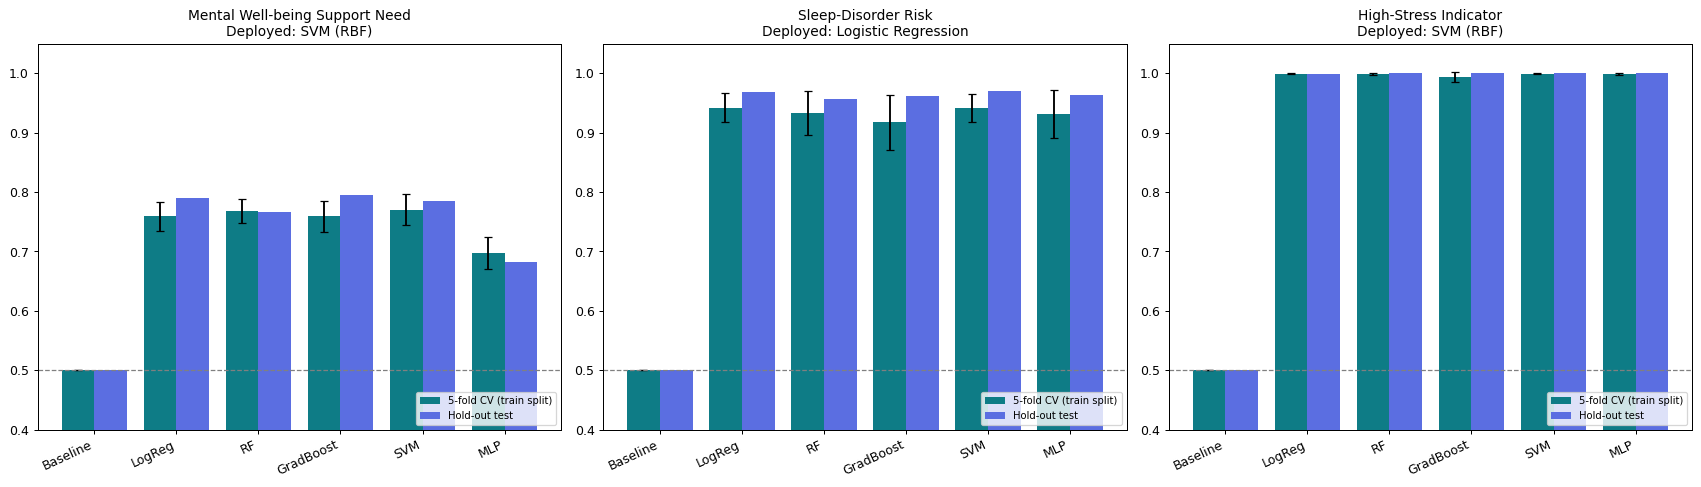

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
short = {"Baseline (majority class)": "Baseline", "Neural Network (MLP)": "MLP", "Logistic Regression": "LogReg",
         "Gradient Boosting": "GradBoost", "Random Forest": "RF", "SVM (RBF)": "SVM"}
for ax, k in zip(axes, TASKS):
    ms = MJ["models"][k]["models"]
    names = [short.get(m["name"], m["name"]) for m in ms]
    x = np.arange(len(names))
    ax.bar(x - 0.2, [m["cv_auc_mean"] for m in ms], 0.4, yerr=[m["cv_auc_std"] for m in ms], capsize=3, label="5-fold CV (train split)", color="#0e7c86")
    ax.bar(x + 0.2, [m["test"]["roc_auc"] for m in ms], 0.4, label="Hold-out test", color="#5b6ee1")
    ax.axhline(0.5, ls="--", c="grey", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=25, ha="right"); ax.set_ylim(0.4, 1.05)
    ax.set_title(f"{TASK_NAME[k]}\nDeployed: {MJ['models'][k]['best_model']}", fontsize=11)
    ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

### 7b. Deployed-model hold-out metrics, ROC curves and confusion matrices

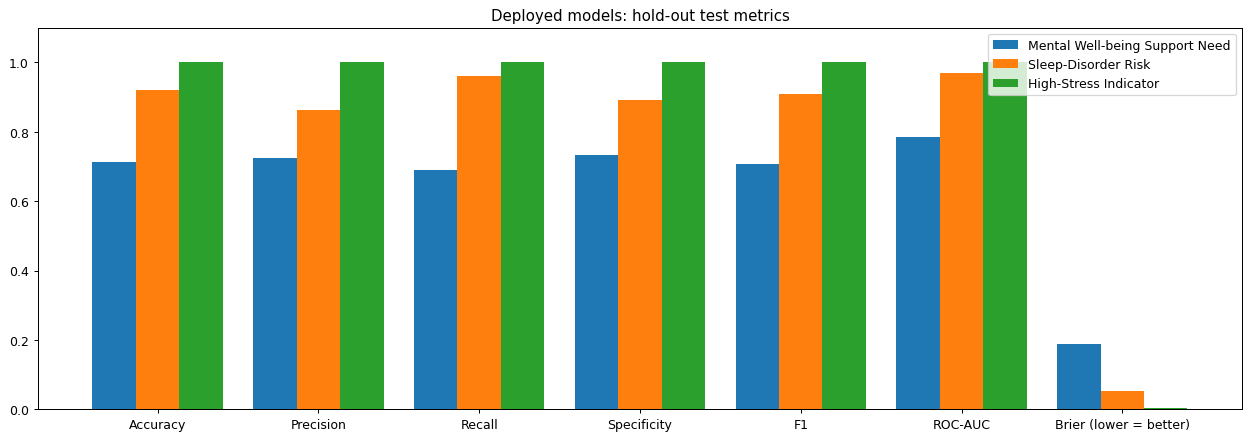

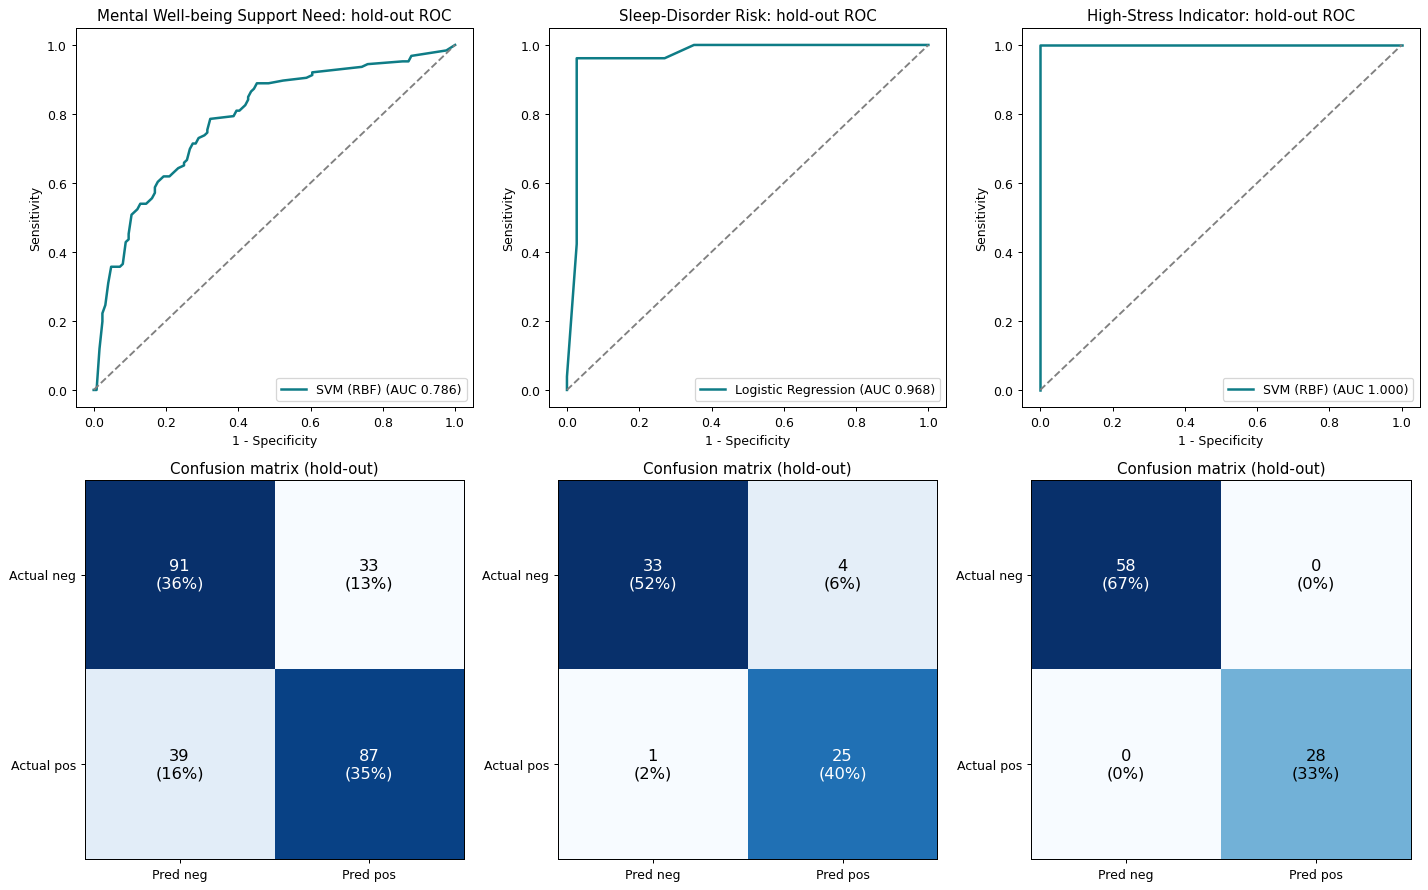

In [27]:
mets = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "brier"]
labels = ["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC", "Brier (lower = better)"]
fig, ax = plt.subplots(figsize=(14, 5)); w = 0.27; x = np.arange(len(mets))
for i, k in enumerate(TASKS):
    ax.bar(x + (i - 1) * w, [MJ["models"][k]["final"]["test"][m] for m in mets], w, label=TASK_NAME[k])
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 1.1); ax.legend()
ax.set_title("Deployed models: hold-out test metrics"); fig.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for c, k in enumerate(TASKS):
    fm = MJ["models"][k]["final"]
    ax = axes[0, c]
    ax.plot(fm["roc"]["fpr"], fm["roc"]["tpr"], lw=2, color="#0e7c86",
            label=f'{MJ["models"][k]["best_model"]} (AUC {fm["test"]["roc_auc"]:.3f})')
    ax.plot([0, 1], [0, 1], "--", c="grey")
    ax.set(title=f"{TASK_NAME[k]}: hold-out ROC", xlabel="1 - Specificity", ylabel="Sensitivity"); ax.legend(loc="lower right")
    ax = axes[1, c]; cm = np.array(fm["confusion"]); tot = cm.sum(); ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}\n({v / tot:.0%})", ha="center", va="center", fontsize=13, color="white" if v > cm.max() / 2 else "black")
    ax.set(title="Confusion matrix (hold-out)", xticks=[0, 1], yticks=[0, 1],
           xticklabels=["Pred neg", "Pred pos"], yticklabels=["Actual neg", "Actual pos"])
fig.tight_layout(); plt.show()

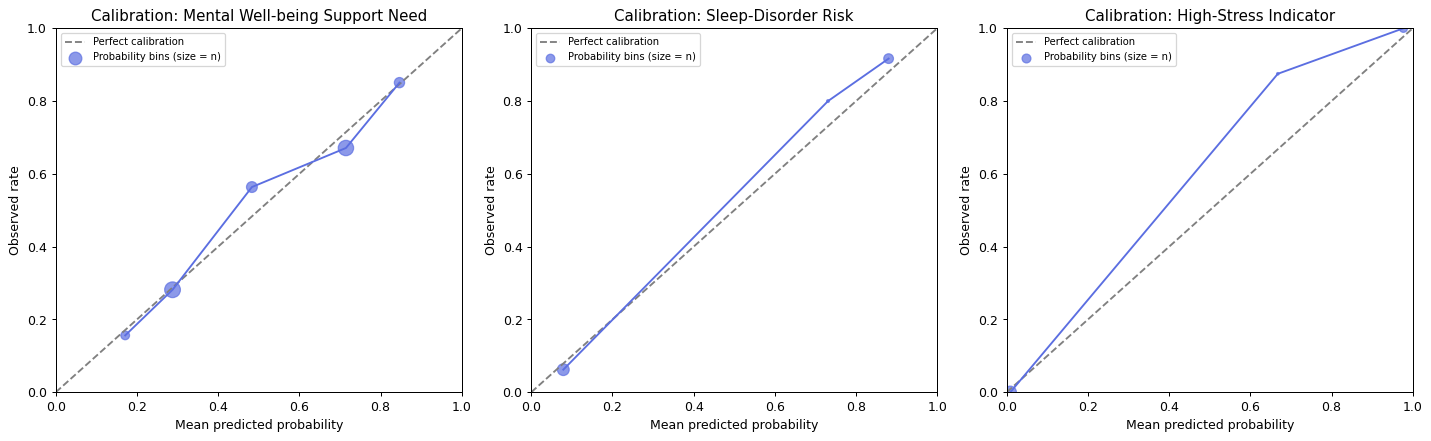

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, k in zip(axes, TASKS):
    cal = MJ["models"][k]["final"]["calibration"]
    px, py = [c["pred"] for c in cal], [c["obs"] for c in cal]
    ax.plot([0, 1], [0, 1], "--", c="grey", label="Perfect calibration")
    ax.plot(px, py, c="#5b6ee1")
    ax.scatter(px, py, s=[c["n"] / 2 for c in cal], alpha=0.7, c="#5b6ee1", label="Probability bins (size = n)")
    ax.set(title=f"Calibration: {TASK_NAME[k]}", xlabel="Mean predicted probability", ylabel="Observed rate", xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

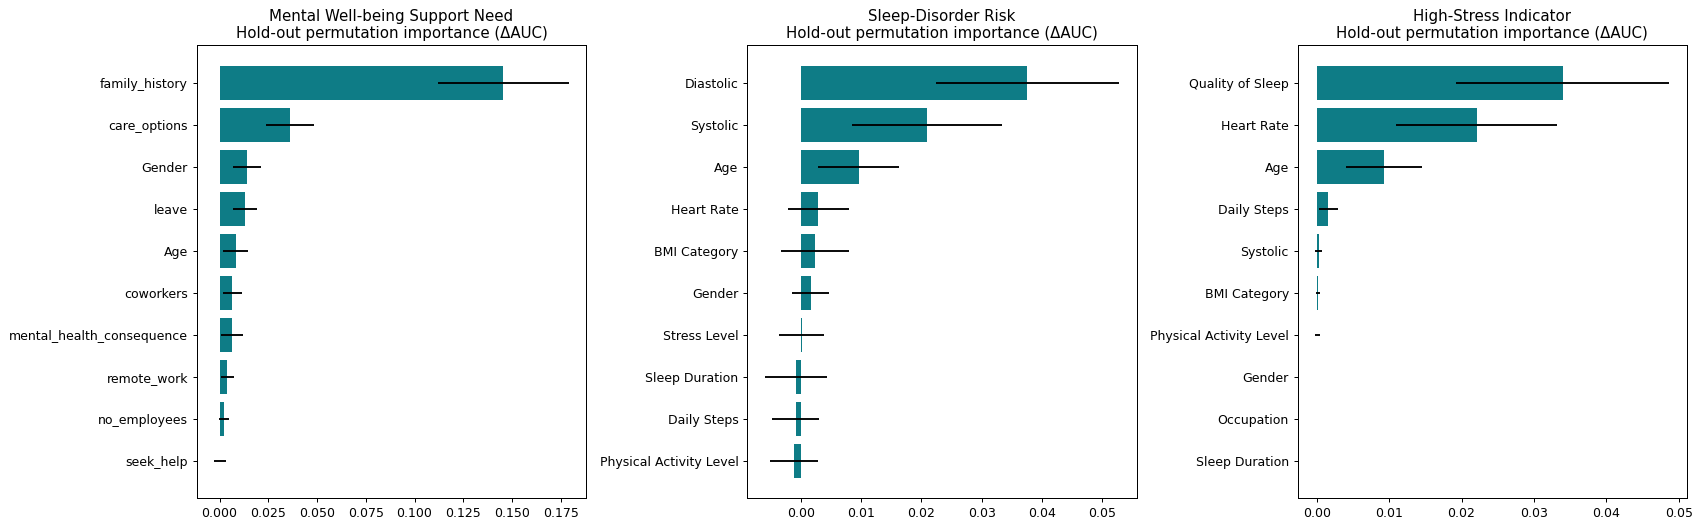

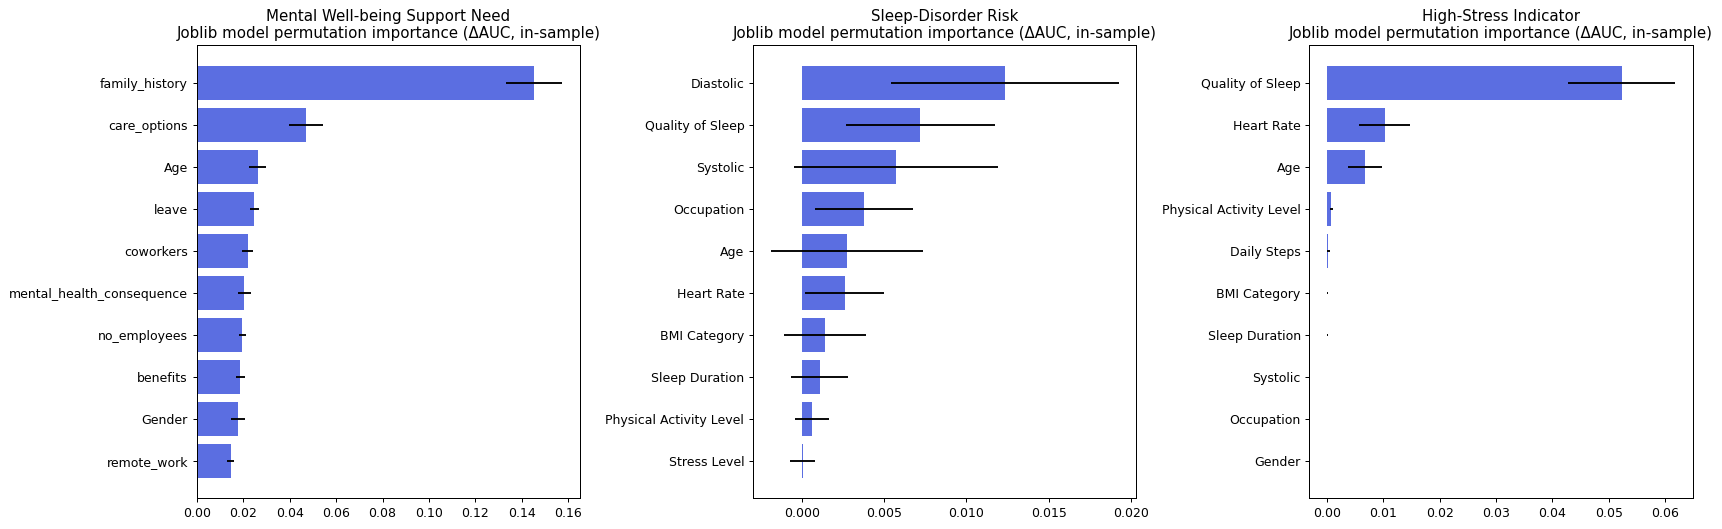

In [29]:
from sklearn.inspection import permutation_importance
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, k in zip(axes, TASKS):
    imp = MJ["models"][k]["final"]["importance"][:10][::-1]
    ax.barh([d["feature"] for d in imp], [d["mean"] for d in imp], xerr=[d["std"] for d in imp], color="#0e7c86")
    ax.set(title=f"{TASK_NAME[k]}\nHold-out permutation importance (ΔAUC)")
fig.tight_layout(); plt.show()

PERM = {}
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, k in zip(axes, TASKS):
    X_, y_, _ = load_task(k)
    pi = permutation_importance(BUNDLES[k]["model"], X_, y_, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
    order = np.argsort(pi.importances_mean)[-10:]
    ax.barh(X_.columns[order], pi.importances_mean[order], xerr=pi.importances_std[order], color="#5b6ee1")
    ax.set(title=f"{TASK_NAME[k]}\nJoblib model permutation importance (ΔAUC, in-sample)")
    PERM[k] = dict(zip(X_.columns, pi.importances_mean))
fig.tight_layout(); plt.show()

### 7e. Interpretability of the deployed sleep model (Logistic Regression coefficients)
Features are standardised, so coefficient size is comparable. Red lowers predicted risk, teal raises it.

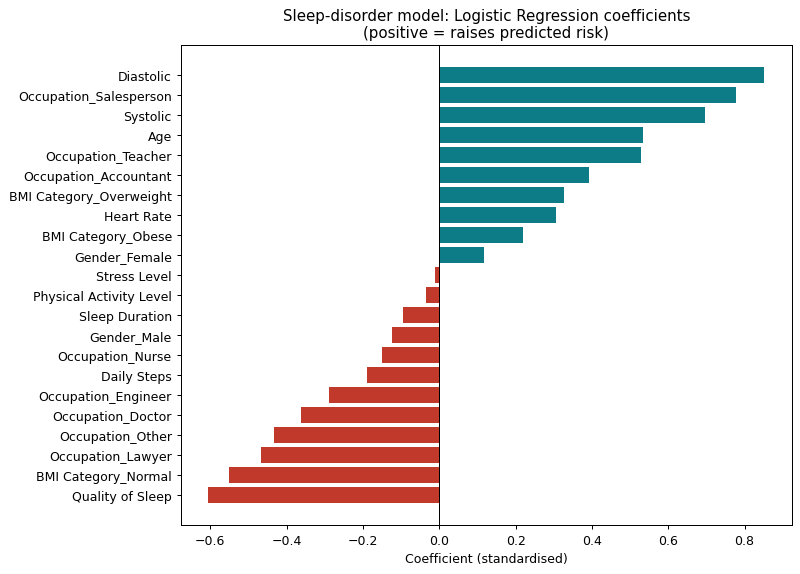

In [30]:
pipe = BUNDLES["sleep"]["model"]
names = [n.split("__", 1)[1] for n in pipe.named_steps["pre"].get_feature_names_out()]
coef = pd.Series(pipe.named_steps["clf"].coef_[0], index=names).sort_values()
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(coef.index, coef.values, color=["#c0392b" if v < 0 else "#0e7c86" for v in coef.values])
ax.axvline(0, c="k", lw=0.8)
ax.set(title="Sleep-disorder model: Logistic Regression coefficients\n(positive = raises predicted risk)", xlabel="Coefficient (standardised)")
fig.tight_layout(); plt.show()

                             Task Profile  P(positive)
0  Mental Well-being Support Need     low     0.126746
1  Mental Well-being Support Need    high     0.856807
2             Sleep-Disorder Risk     low     0.017397
3             Sleep-Disorder Risk    high     0.972567
4           High-Stress Indicator     low     0.000707
5           High-Stress Indicator    high     0.994285

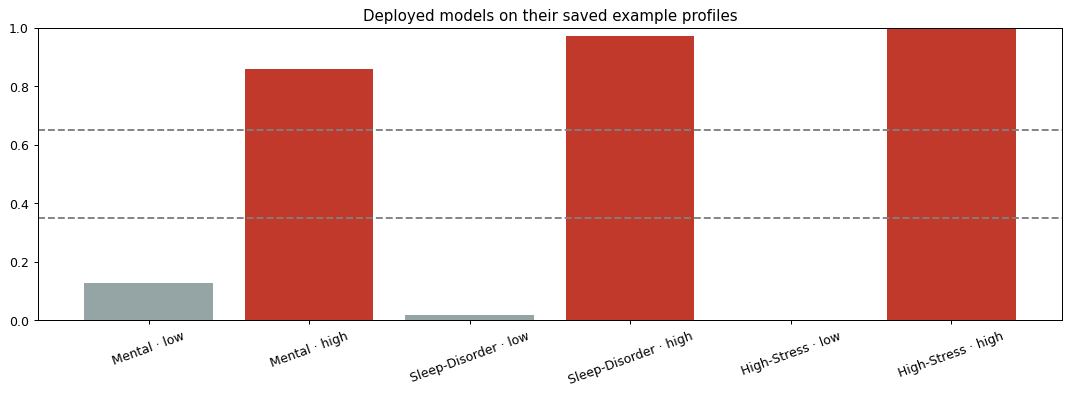

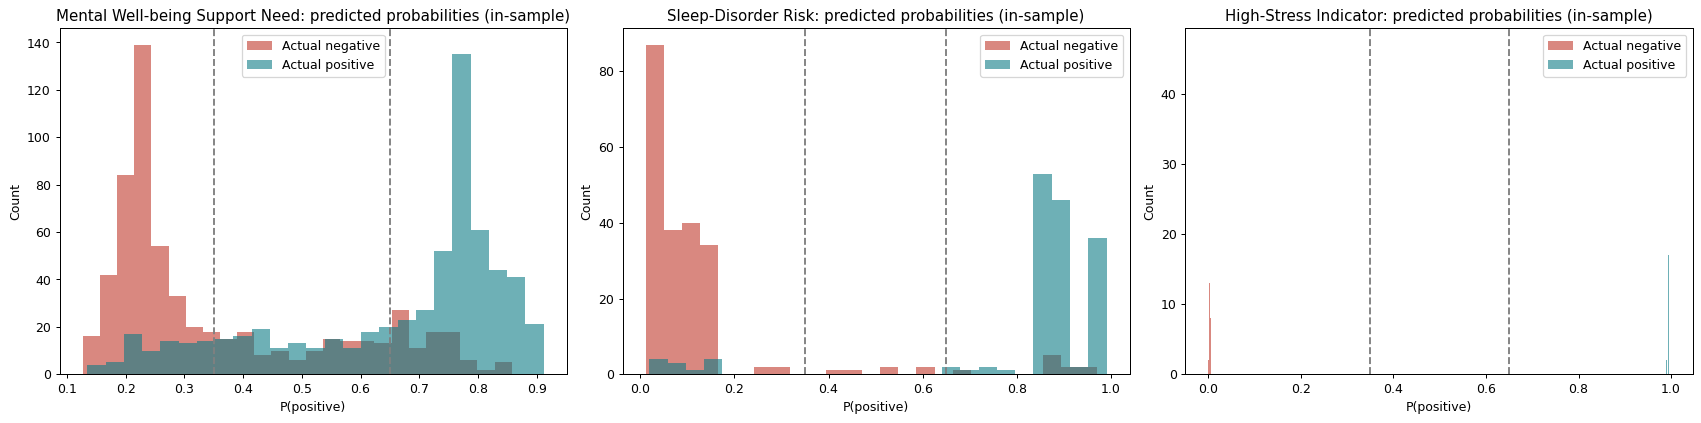

In [31]:
ex = []
for k in TASKS:
    b = BUNDLES[k]
    for lvl in ["low", "high"]:
        df_ex = pd.DataFrame([b["examples"][lvl]])[b["features"]]
        ex.append({"Task": TASK_NAME[k], "Profile": lvl, "P(positive)": float(b["model"].predict_proba(df_ex)[0, 1])})
ex_df = pd.DataFrame(ex); display(ex_df)

fig, ax = plt.subplots(figsize=(12, 4.5))
lab_idx = np.arange(len(ex_df)); ax.bar(lab_idx, ex_df["P(positive)"], color=["#95a5a6" if p == "low" else "#c0392b" for p in ex_df["Profile"]])
ax.axhline(0.35, ls="--", c="grey"); ax.axhline(0.65, ls="--", c="grey"); ax.set_ylim(0, 1)
ax.set_xticks(lab_idx); ax.set_xticklabels([f"{t.split()[0]} · {p}" for t, p in zip(ex_df["Task"], ex_df["Profile"])], rotation=20)
ax.set_title("Deployed models on their saved example profiles"); fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, k in zip(axes, TASKS):
    X_, y_, _ = load_task(k)
    p = BUNDLES[k]["model"].predict_proba(X_)[:, 1]
    ax.hist(p[y_ == 0], bins=25, alpha=0.6, color="#c0392b", label="Actual negative")
    ax.hist(p[y_ == 1], bins=25, alpha=0.6, color="#0e7c86", label="Actual positive")
    ax.axvline(0.35, ls="--", c="grey"); ax.axvline(0.65, ls="--", c="grey")
    ax.set(title=f"{TASK_NAME[k]}: predicted probabilities (in-sample)", xlabel="P(positive)", ylabel="Count"); ax.legend()
fig.tight_layout(); plt.show()

## 8. Data exploration charts

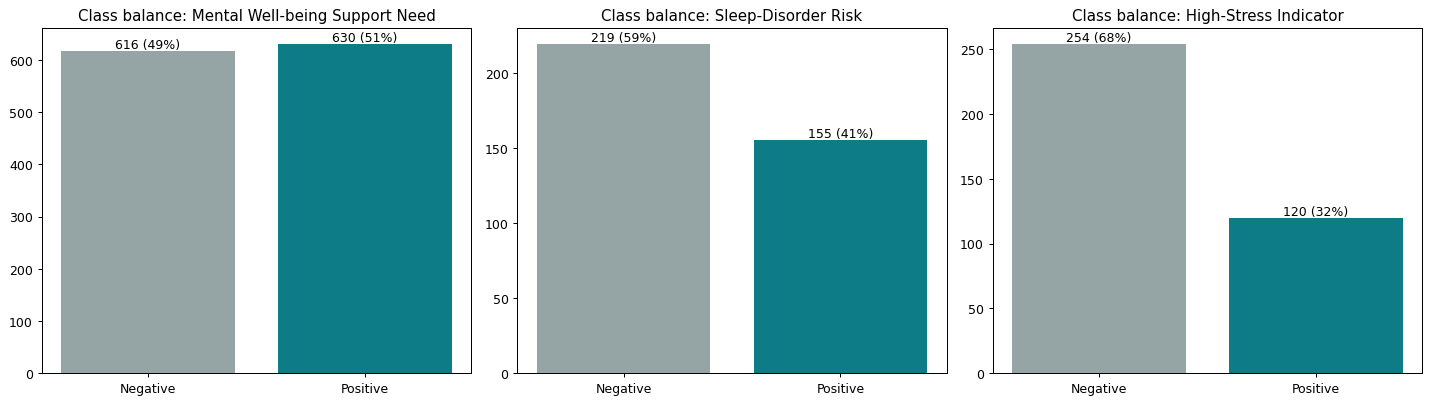

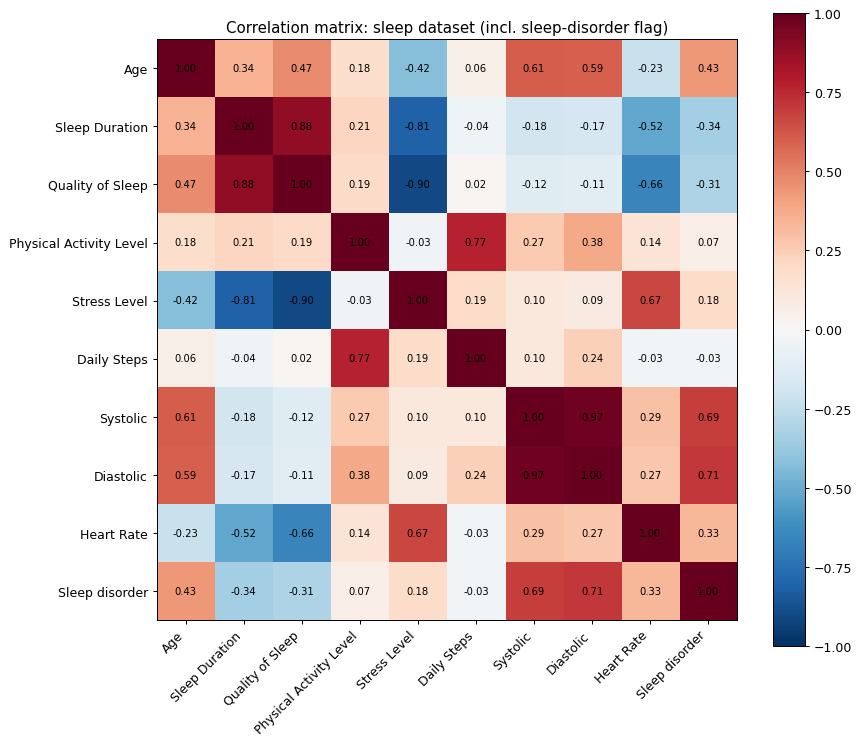

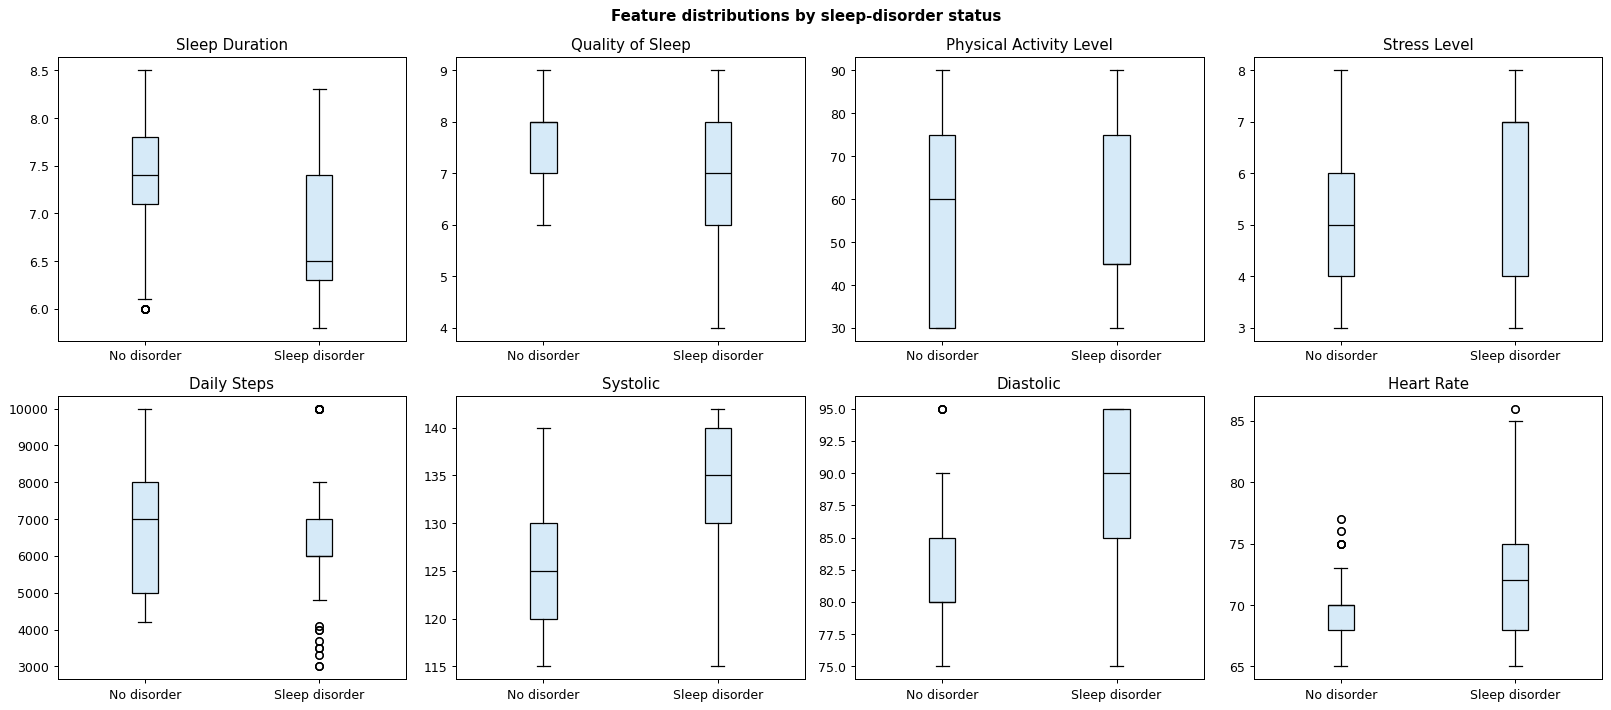

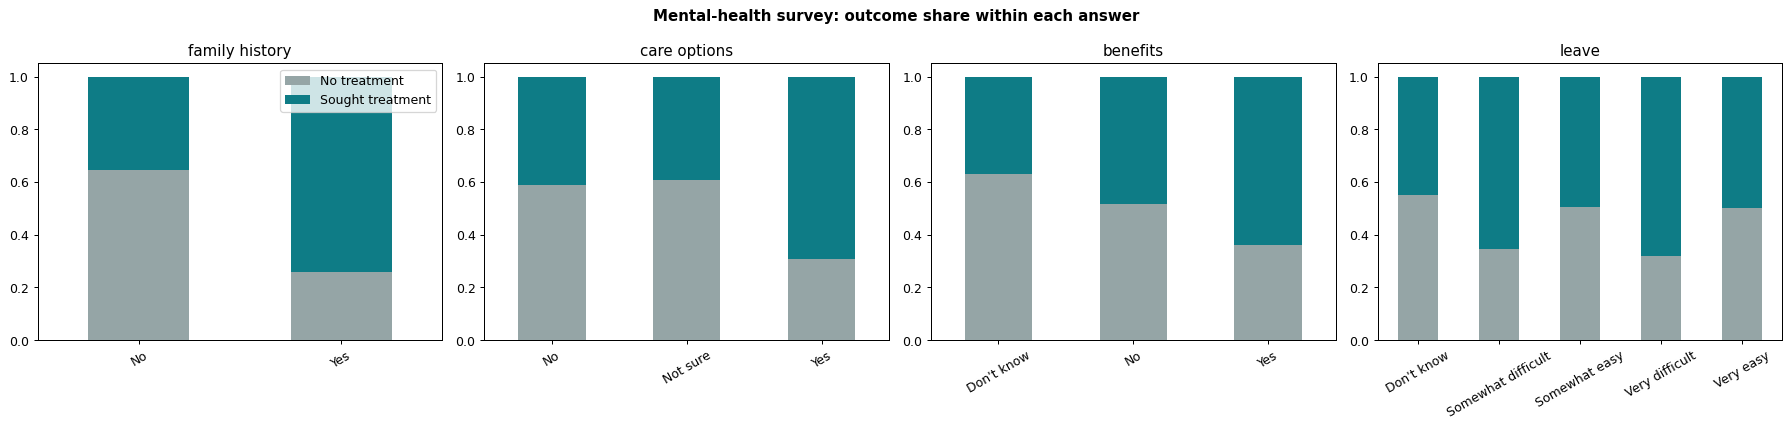

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, t in zip(axes, TASKS):
    y_ = RESULTS[t]["y"]; vc = y_.value_counts().sort_index()
    ax.bar(["Negative", "Positive"], vc.values, color=["#95a5a6", "#0e7c86"])
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v} ({v / len(y_):.0%})", ha="center", va="bottom")
    ax.set_title(f"Class balance: {TASK_NAME[t]}")
fig.tight_layout(); plt.show()

sleep_df = sleep_base()
num_cols = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level", "Stress Level", "Daily Steps", "Systolic", "Diastolic", "Heart Rate"]
cdf = sleep_df[num_cols].copy(); cdf["Sleep disorder"] = sleep_df["Sleep Disorder"].notna().astype(int)
corr = cdf.corr()
fig, ax = plt.subplots(figsize=(10, 8.5)); im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation matrix: sleep dataset (incl. sleep-disorder flag)")
fig.tight_layout(); plt.show()

lab = sleep_df["Sleep Disorder"].notna()
feats = ["Sleep Duration", "Quality of Sleep", "Physical Activity Level", "Stress Level", "Daily Steps", "Systolic", "Diastolic", "Heart Rate"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), feats):
    ax.boxplot([sleep_df.loc[~lab, f], sleep_df.loc[lab, f]], patch_artist=True,
               boxprops=dict(facecolor="#d6eaf8"), medianprops=dict(color="black"))
    ax.set_xticks([1, 2]); ax.set_xticklabels(["No disorder", "Sleep disorder"]); ax.set_title(f)
fig.suptitle("Feature distributions by sleep-disorder status", fontweight="bold"); fig.tight_layout(); plt.show()

Xm, ym, _ = load_task("mental")
mcols = ["family_history", "care_options", "benefits", "leave"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for c, (ax, col) in enumerate(zip(axes, mcols)):
    ct = pd.crosstab(Xm[col], ym, normalize="index"); ct.columns = ["No treatment", "Sought treatment"]
    ct.plot(kind="bar", stacked=True, ax=ax, color=["#95a5a6", "#0e7c86"], legend=(c == 0))
    ax.set(title=col.replace("_", " "), xlabel=""); ax.tick_params(axis="x", rotation=30)
fig.suptitle("Mental-health survey: outcome share within each answer", fontweight="bold"); fig.tight_layout(); plt.show()

## 9. Evaluation charts from the nested CV run

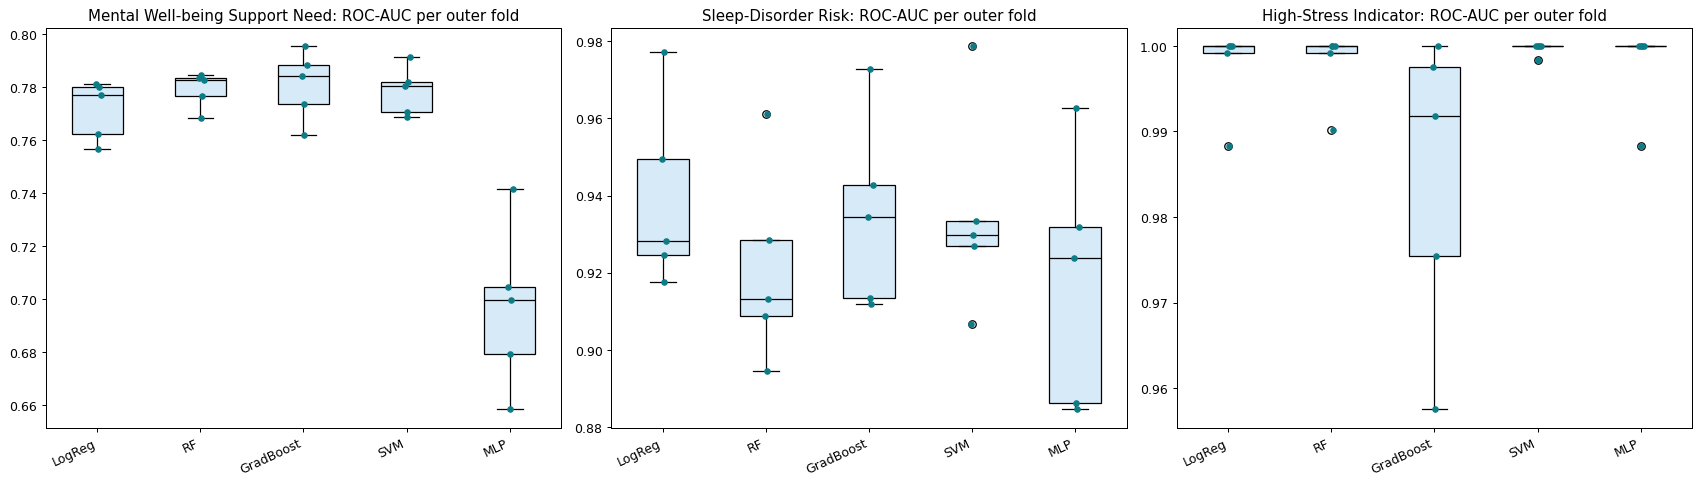

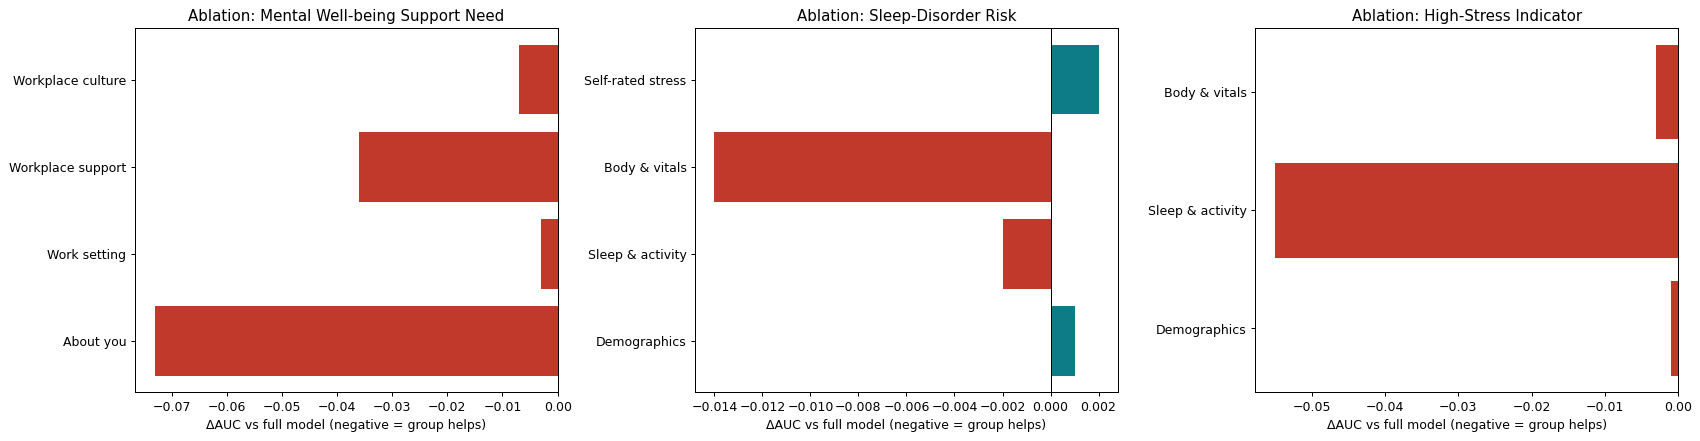

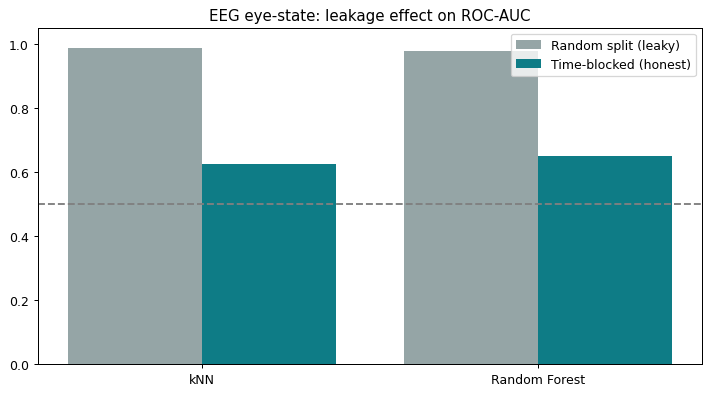

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, t in zip(axes, TASKS):
    names = MODEL_ORDER[1:]
    data = [RESULTS[t]["folds"][n]["ROC_AUC"].values for n in names]
    ax.boxplot(data, patch_artist=True, boxprops=dict(facecolor="#d6eaf8"), medianprops=dict(color="black"))
    for i, d in enumerate(data):
        ax.scatter(np.full(len(d), i + 1) + np.random.RandomState(0).uniform(-0.08, 0.08, len(d)), d, s=18, c="#0e7c86", zorder=3)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels([short.get(n, n) for n in names], rotation=25, ha="right")
    ax.set_title(f"{TASK_NAME[t]}: ROC-AUC per outer fold")
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, t in zip(axes, TASKS):
    a = ABLATION[t]; a = a[a["Removed"] != "None (full model)"]
    ax.barh(a["Removed"], a["Delta_AUC"], color=["#c0392b" if v < 0 else "#0e7c86" for v in a["Delta_AUC"]])
    ax.axvline(0, c="k", lw=0.8)
    ax.set(title=f"Ablation: {TASK_NAME[t]}", xlabel="ΔAUC vs full model (negative = group helps)")
fig.tight_layout(); plt.show()

eeg = MJ["eeg_study"]["results"]; names_e = list(eeg); xe = np.arange(len(names_e))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(xe - 0.2, [eeg[n]["random_split"]["roc_auc"] for n in names_e], 0.4, label="Random split (leaky)", color="#95a5a6")
ax.bar(xe + 0.2, [eeg[n]["blocked_split"]["roc_auc"] for n in names_e], 0.4, label="Time-blocked (honest)", color="#0e7c86")
ax.axhline(0.5, ls="--", c="grey"); ax.set_xticks(xe); ax.set_xticklabels(names_e); ax.set_ylim(0, 1.05)
ax.set_title("EEG eye-state: leakage effect on ROC-AUC"); ax.legend(); fig.tight_layout(); plt.show()